# Dual-Branch ALBERT + GIN Email Classification
## Multi-Class (HAM / SPAM / PHISHING) & Phishing Subtype Detection

### Architecture & Capabilities
This notebook implements a state-of-the-art **dual-branch multimodal architecture**:
1. **Transformer Branch (ALBERT)**: Extracts deep contextual token representations from email subjects and bodies using `albert-large-v2` with intermediate layer hidden states.
2. **Graph Isomorphism Network (GIN) Branch**: Models relational topologies (senders, receivers, domains, hyperlinks, SPF/DKIM flags) using multi-hop permutation-invariant message passing.
3. **Gated Multimodal Fusion**: Dynamically balances semantic vs. topological signals.
4. **Multi-Task Heads**: Simultaneous primary 3-class classification and 10-class phishing subtype classification.

### Hardware & Output Configuration
- **Hardware**: Optimized for Kaggle's **2x Tesla T4 GPUs** using `torch.nn.DataParallel` and mixed precision (`torch.amp.autocast`).
- **Live Cell Outputs**: Detailed layer activation statistics (shapes, means, stds, L2 norms, sparsity) are printed directly in the notebook cell outputs.
- **Output Directory (`./output/`)**: All artifacts are automatically structured and saved:
  - `./output/checkpoints/` (Best model weights)
  - `./output/embeddings/` (Text, Graph, Fused embeddings)
  - `./output/layer_outputs/` (ALBERT & GIN layer states and summary tables)
  - `./output/metrics/` (Classification reports, confusion matrices, epoch history)
  - `./output/images/` (Training curves, confusion matrices, t-SNE, layer activations)
  - `./output/tables/` (Markdown & LaTeX summary tables)


In [1]:
# ==============================================================================
# 1. Environment Setup & Dependency Installation
# ==============================================================================
import sys
import subprocess

def install_package(pkg):
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
    except Exception as e:
        print(f"Note: Could not install {pkg}: {e}")

print("Checking and installing required dependencies...")
install_package("transformers>=4.30.0")
install_package("scikit-learn>=1.2.0")
install_package("seaborn>=0.12.0")
install_package("tabulate>=0.9.0")

print("All dependencies checked.")


Checking and installing required dependencies...
All dependencies checked.


In [2]:
# ==============================================================================
# 2. Hardware Verification & Directory Setup (2x T4 GPUs)
# ==============================================================================
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import random
import numpy as np
import torch

# Set deterministic seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = True

# Detect GPU resources
device_count = torch.cuda.device_count()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 70)
print(f"PyTorch Version : {torch.__version__}")
print(f"CUDA Available  : {torch.cuda.is_available()}")
print(f"Device Count    : {device_count}")
for i in range(device_count):
    props = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {props.name} | VRAM: {props.total_memory / (1024**3):.2f} GB | Compute: {props.major}.{props.minor}")
print(f"Primary Device  : {device}")
if device_count >= 2:
    print(">>> Multi-GPU Mode: 2x T4 GPUs detected! DataParallel will be utilized.")
else:
    print(">>> Single-GPU/CPU Mode.")
print("=" * 70)

# Setup Output Directory Structure
OUTPUT_DIR = "./output"
SUBDIRS = ["checkpoints", "embeddings", "layer_outputs", "metrics", "images", "tables"]

for sub in SUBDIRS:
    path = os.path.join(OUTPUT_DIR, sub)
    os.makedirs(path, exist_ok=True)
    print(f"Created/verified directory: {path}")

print("\nOutput directory hierarchy successfully established under ./output/")


PyTorch Version : 2.10.0+cu128
CUDA Available  : True
Device Count    : 2
  GPU 0: Tesla T4 | VRAM: 14.56 GB | Compute: 7.5
  GPU 1: Tesla T4 | VRAM: 14.56 GB | Compute: 7.5
Primary Device  : cuda
>>> Multi-GPU Mode: 2x T4 GPUs detected! DataParallel will be utilized.
Created/verified directory: ./output/checkpoints
Created/verified directory: ./output/embeddings
Created/verified directory: ./output/layer_outputs
Created/verified directory: ./output/metrics
Created/verified directory: ./output/images
Created/verified directory: ./output/tables

Output directory hierarchy successfully established under ./output/


In [3]:
# ==============================================================================
# 3. Dataset Loading & Path Resolution
# ==============================================================================
import pandas as pd
import glob
import json

def find_dataset():
    candidates = [
        "/kaggle/input/augmented-66k/augmented_66k.parquet",
        "/kaggle/input/**/augmented_66k.parquet",
        "/kaggle/input/**/*.parquet",
        "./dataset/augmented_dataset/augmented_66k.parquet",
        "./augmented_66k.parquet",
        "../dataset/augmented_dataset/augmented_66k.parquet",
        "c:/Users/acer/Desktop/rev2tasks/dataset/augmented_dataset/augmented_66k.parquet"
    ]
    for cand in candidates:
        matches = glob.glob(cand, recursive=True)
        for m in matches:
            if os.path.exists(m) and os.path.isfile(m) and "augmented" in m:
                return m
    for cand in candidates:
        matches = glob.glob(cand, recursive=True)
        if matches:
            return matches[0]
    raise FileNotFoundError("Could not locate augmented_66k.parquet. Please upload or specify path.")

DATASET_PATH = find_dataset()
print(f"Loading dataset from: {DATASET_PATH}")
df = pd.read_parquet(DATASET_PATH)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Missing Values: {df.isnull().sum().sum()} total across all columns")

# Label mappings
PRIMARY_LABELS = {"HAM": 0, "PHISHING": 1, "SPAM": 2}
PRIMARY_ID2LABEL = {v: k for k, v in PRIMARY_LABELS.items()}

# Extract unique subtypes ensuring NOT_PHISHING is index 0
subtypes = sorted([s for s in df["phishing_subtype"].unique() if s != "NOT_PHISHING"])
SUBTYPE_LABELS = {"NOT_PHISHING": 0}
for idx, s in enumerate(subtypes, start=1):
    SUBTYPE_LABELS[s] = idx
SUBTYPE_ID2LABEL = {v: k for k, v in SUBTYPE_LABELS.items()}

df["primary_target"] = df["primary_label"].map(PRIMARY_LABELS)
df["subtype_target"] = df["phishing_subtype"].map(SUBTYPE_LABELS)

print("\n--- Primary Label Distribution ---")
for k, v in df["primary_label"].value_counts().items():
    print(f"  {k:10s}: {v:6d} ({v/len(df)*100:.2f}%)")

print("\n--- Phishing Subtype Distribution ---")
for k, v in df[df["primary_label"]=="PHISHING"]["phishing_subtype"].value_counts().items():
    print(f"  {k:25s}: {v:6d} ({v/len(df)*100:.2f}%)")

# Save label mappings to output
with open(os.path.join(OUTPUT_DIR, "metrics", "label_mapping.json"), "w") as f:
    json.dump({
        "primary_labels": PRIMARY_ID2LABEL,
        "subtype_labels": SUBTYPE_ID2LABEL
    }, f, indent=2)
print("\nLabel mappings saved to ./output/metrics/label_mapping.json")


Loading dataset from: /kaggle/input/datasets/lingeshwarshivakumar/augmented-66k-parquet/augmented_66k.parquet
Dataset Shape: 66000 rows, 16 columns
Missing Values: 0 total across all columns

--- Primary Label Distribution ---
  HAM       :  22000 (33.33%)
  SPAM      :  22000 (33.33%)
  PHISHING  :  22000 (33.33%)

--- Phishing Subtype Distribution ---
  GENERIC_PHISHING         :  13921 (21.09%)
  GOVERNMENT_PHISHING      :   1664 (2.52%)
  MALWARE_DELIVERY         :   1485 (2.25%)
  BEC                      :   1262 (1.91%)
  DELIVERY_PHISHING        :   1229 (1.86%)
  FINANCIAL_PHISHING       :   1075 (1.63%)
  CREDENTIAL_PHISHING      :    861 (1.30%)
  TECH_SUPPORT_PHISHING    :    500 (0.76%)
  SURVEY_PHISHING          :      3 (0.00%)

Label mappings saved to ./output/metrics/label_mapping.json


In [4]:
# ==============================================================================
# 4. Graph Construction & Node Featurization for GIN
# ==============================================================================
# Each email is constructed as an attributed entity graph:
# Nodes:
#   0: Sender Node
#   1: Receiver Node
#   2: Sender Domain Node
#   3..K: Destination Domain / Hyperlink Nodes
# Node Features (Dimension = 16):
#   - [0..3]: One-hot Entity Type (0=Sender, 1=Receiver, 2=Domain, 3=URL)
#   - [4]: SPF Authentication (0 or 1)
#   - [5]: DKIM Authentication (0 or 1)
#   - [6]: Normalized num_urls
#   - [7]: Normalized num_domains
#   - [8]: Normalized body_length
#   - [9..15]: Reserved / Identity feature hash indicators

def build_email_graph(row):
    # Parse destination domains
    try:
        if isinstance(row["domains"], str):
            domains_list = json.loads(row["domains"]) if row["domains"].startswith("[") else [row["domains"]]
        else:
            domains_list = list(row["domains"])
    except:
        domains_list = []
    
    # Cap to max 10 external domain nodes per graph for consistency
    domains_list = domains_list[:10]
    num_nodes = 3 + len(domains_list)
    
    # Fixed-size node feature matrix [14, 16] and adjacency matrix [14, 14]
    MAX_GRAPH_NODES = 14
    features = np.zeros((MAX_GRAPH_NODES, 16), dtype=np.float32)
    adj = np.zeros((MAX_GRAPH_NODES, MAX_GRAPH_NODES), dtype=np.float32)
    
    # Node 0: Sender
    features[0, 0] = 1.0
    features[0, 4] = float(row.get("has_spf", 0))
    features[0, 5] = float(row.get("has_dkim", 0))
    features[0, 6] = min(float(row.get("num_urls", 0)) / 10.0, 1.0)
    features[0, 7] = min(float(row.get("num_domains", 0)) / 10.0, 1.0)
    features[0, 8] = min(float(row.get("body_length", 0)) / 5000.0, 1.0)
    
    # Node 1: Receiver
    features[1, 1] = 1.0
    features[1, 8] = features[0, 8]
    
    # Node 2: Sender Domain
    features[2, 2] = 1.0
    features[2, 4] = features[0, 4]
    features[2, 5] = features[0, 5]
    
    # Node 3..K: Destination Domains
    for i in range(len(domains_list)):
        idx = 3 + i
        features[idx, 3] = 1.0
        features[idx, 6] = 1.0 / (i + 1)
        adj[1, idx] = 1.0
        adj[idx, 1] = 1.0
    
    # Core bidirectional edges (Sender <-> SenderDomain, Sender <-> Receiver)
    adj[0, 2] = 1.0; adj[2, 0] = 1.0
    adj[0, 1] = 1.0; adj[1, 0] = 1.0
    
    return features, adj, num_nodes

print("Graph featurization function defined successfully.")
sample_feat, sample_adj, sample_n = build_email_graph(df.iloc[0])
print(f"Sample Graph: {sample_n} active nodes, feat shape: {sample_feat.shape}, adj shape: {sample_adj.shape}")


Graph featurization function defined successfully.
Sample Graph: 4 active nodes, feat shape: (14, 16), adj shape: (14, 14)


In [5]:
# ==============================================================================
# 5. Dataset, Tokenization & Multi-Modal Collate Function
# ==============================================================================
from transformers import AutoTokenizer
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

TOKENIZER_NAME = "albert-large-v2"
MAX_LEN = 256
BATCH_SIZE = 16  # 16 total (8 per GPU on 2x T4 GPUs for safe VRAM headroom)

print(f"Loading ALBERT tokenizer: {TOKENIZER_NAME}...")
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)

class EmailMultiModalDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_len=256):
        self.df = dataframe.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len = max_len
        
    def __len__(self):
        return len(self.df)
        
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        
        # Combine subject and body text
        subject_text = str(row["subject"]) if row["subject"] else ""
        body_text = str(row["body_clean"]) if row["body_clean"] else ""
        full_text = f"Subject: {subject_text} | Message: {body_text}"
        
        # Tokenize for ALBERT
        tokens = self.tokenizer(
            full_text,
            max_length=self.max_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )
        
        # Build Graph with fixed shape [14, 16] and adj [14, 14]
        node_feats, adj, num_nodes = build_email_graph(row)
        
        return {
            "input_ids": tokens["input_ids"].squeeze(0),
            "attention_mask": tokens["attention_mask"].squeeze(0),
            "node_feats": torch.from_numpy(node_feats),
            "adj": torch.from_numpy(adj),
            "num_nodes": num_nodes,
            "primary_target": torch.tensor(row["primary_target"], dtype=torch.long),
            "subtype_target": torch.tensor(row["subtype_target"], dtype=torch.long),
        }

def collate_multimodal_batch(batch):
    input_ids = torch.stack([b["input_ids"] for b in batch])
    attention_mask = torch.stack([b["attention_mask"] for b in batch])
    node_feats = torch.stack([b["node_feats"] for b in batch])
    adj = torch.stack([b["adj"] for b in batch])
    primary_targets = torch.stack([b["primary_target"] for b in batch])
    subtype_targets = torch.stack([b["subtype_target"] for b in batch])
    
    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "node_feats": node_feats,
        "adj": adj,
        "batch_size": len(batch),
        "primary_targets": primary_targets,
        "subtype_targets": subtype_targets
    }

# Stratified Split: 70% Train, 15% Val, 15% Test
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df["primary_target"])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["primary_target"])

print(f"Data Splits: Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")

train_dataset = EmailMultiModalDataset(train_df, tokenizer, max_len=MAX_LEN)
val_dataset = EmailMultiModalDataset(val_df, tokenizer, max_len=MAX_LEN)
test_dataset = EmailMultiModalDataset(test_df, tokenizer, max_len=MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_multimodal_batch, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_multimodal_batch, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_multimodal_batch, num_workers=2, pin_memory=True)

print(f"DataLoaders Ready: {len(train_loader)} train batches per epoch.")


Loading ALBERT tokenizer: albert-large-v2...


config.json:   0%|          | 0.00/685 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/760k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Data Splits: Train=46200, Val=9900, Test=9900
DataLoaders Ready: 2888 train batches per epoch.


In [6]:
# ==============================================================================
# 6. Dual-Branch Model Architecture: ALBERT + GIN + Gated Fusion
# ==============================================================================
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModel

class GINLayer(nn.Module):
    """Batched Graph Isomorphism Network (GIN) Convolution Layer with 2-layer MLP"""
    def __init__(self, in_dim, out_dim, eps=0.0):
        super().__init__()
        self.eps = nn.Parameter(torch.Tensor([eps]))
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, out_dim),
            nn.BatchNorm1d(out_dim),
            nn.ReLU(),
            nn.Linear(out_dim, out_dim),
            nn.BatchNorm1d(out_dim),
            nn.ReLU()
        )
        
    def forward(self, x, adj):
        # x: [B, N, D], adj: [B, N, N]
        # Permutation-invariant sum aggregation via batched matrix multiply
        agg = torch.bmm(adj, x)
        out = (1.0 + self.eps) * x + agg
        B, N, D = out.shape
        out_flat = self.mlp(out.view(B * N, D))
        return out_flat.view(B, N, -1)

class GINBranch(nn.Module):
    """3-Layer Batched GIN with Jumping Knowledge (JK) multi-layer representations"""
    def __init__(self, in_dim=16, hidden_dim=64, num_layers=3):
        super().__init__()
        self.layers = nn.ModuleList()
        self.layers.append(GINLayer(in_dim, hidden_dim))
        for _ in range(num_layers - 1):
            self.layers.append(GINLayer(hidden_dim, hidden_dim))
        self.out_dim = hidden_dim * 2  # Mean pool + Max pool
        
    def forward(self, x, adj):
        layer_reps = [x]
        curr = x
        for layer in self.layers:
            curr = layer(curr, adj)
            layer_reps.append(curr)
            
        # Global Graph Readout (Mean + Max pooling per graph across nodes dim 1)
        mean_pool = curr.mean(dim=1)
        max_pool = curr.max(dim=1)[0]
        graph_embed = torch.cat([mean_pool, max_pool], dim=-1)
        return graph_embed, layer_reps

class GatedMultimodalFusion(nn.Module):
    """Gated fusion combining text and graph embeddings"""
    def __init__(self, text_dim=1024, graph_dim=128, fused_dim=256):
        super().__init__()
        self.proj_text = nn.Linear(text_dim, fused_dim)
        self.proj_graph = nn.Linear(graph_dim, fused_dim)
        self.gate = nn.Sequential(
            nn.Linear(text_dim + graph_dim, fused_dim),
            nn.Sigmoid()
        )
        self.out_proj = nn.Sequential(
            nn.Linear(fused_dim, fused_dim),
            nn.LayerNorm(fused_dim),
            nn.ReLU(),
            nn.Dropout(0.2)
        )
        
    def forward(self, z_text, z_graph):
        h_t = self.proj_text(z_text)
        h_g = self.proj_graph(z_graph)
        alpha = self.gate(torch.cat([z_text, z_graph], dim=-1))
        fused = alpha * h_t + (1.0 - alpha) * h_g
        return self.out_proj(fused)

class AlbertGINClassifier(nn.Module):
    """Complete Dual-Branch Architecture with Memory-Optimized Layer Tracking"""
    def __init__(self, albert_model_name="albert-large-v2", num_primary=3, num_subtypes=10, fused_dim=256):
        super().__init__()
        self.albert = AutoModel.from_pretrained(albert_model_name)
        albert_dim = self.albert.config.hidden_size  # Automatically 1024 for albert-large-v2
        self.gin = GINBranch(in_dim=16, hidden_dim=64, num_layers=3)
        self.fusion = GatedMultimodalFusion(text_dim=albert_dim, graph_dim=128, fused_dim=fused_dim)
        
        # Multi-task Classification Heads
        self.primary_head = nn.Sequential(
            nn.Linear(fused_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_primary)
        )
        self.subtype_head = nn.Sequential(
            nn.Linear(fused_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_subtypes)
        )
        
    def forward(self, input_ids, attention_mask, node_feats, adj, return_layers=False):
        # 1. ALBERT Forward Pass (CRITICAL: output_hidden_states ONLY when return_layers=True)
        albert_out = self.albert(
            input_ids=input_ids,
            attention_mask=attention_mask,
            output_hidden_states=return_layers
        )
        z_text = albert_out.last_hidden_state[:, 0, :]  # [CLS] representation [B, 1024]
        
        # 2. Batched GIN Forward Pass
        z_graph, gin_layer_reps = self.gin(node_feats, adj)  # [B, 128]
        
        # 3. Gated Fusion
        z_fused = self.fusion(z_text, z_graph)  # [B, 256]
        
        # 4. Multi-Task Logits
        logits_primary = self.primary_head(z_fused)
        logits_subtype = self.subtype_head(z_fused)
        
        if return_layers:
            return {
                "logits_primary": logits_primary,
                "logits_subtype": logits_subtype,
                "z_text": z_text,
                "z_graph": z_graph,
                "z_fused": z_fused,
                "transformer_layers": albert_out.hidden_states,
                "gin_layers": gin_layer_reps
            }
            
        return logits_primary, logits_subtype, z_fused

print("AlbertGINClassifier architecture defined successfully.")


AlbertGINClassifier architecture defined successfully.


In [7]:
# ==============================================================================
# 7. Detailed Layer Output Inspector & Cell Printer
# ==============================================================================
from tabulate import tabulate

def inspect_and_print_layer_outputs(model_output, save_dir=os.path.join(OUTPUT_DIR, "layer_outputs")):
    """
    Extracts detailed statistics for all ALBERT transformer layers and GIN layers,
    prints formatted tables directly to the notebook cell output, and persists to disk.
    """
    trans_layers = model_output["transformer_layers"]
    gin_layers = model_output["gin_layers"]
    z_fused = model_output["z_fused"]
    
    table_data = []
    summary_dict = {}
    
    print("\n" + "=" * 95)
    print("                      DETAILED LAYER OUTPUTS & ACTIVATION ANALYSIS")
    print("=" * 95)
    
    # 1. ALBERT Transformer Layers Analysis
    print("\n>>> [BRANCH 1] ALBERT TRANSFORMER LAYERS (24 Encoder Layers + Embedding Layer):")
    for i, h in enumerate(trans_layers):
        layer_name = "Embedding" if i == 0 else f"ALBERT-Layer-{i:02d}"
        t = h.detach().cpu()
        shape_str = str(list(t.shape))
        mean_val = float(t.mean())
        std_val = float(t.std())
        min_val = float(t.min())
        max_val = float(t.max())
        l2_norm = float(torch.norm(t, p=2) / np.sqrt(t.numel()))
        sparsity = float((t.abs() < 1e-4).float().mean() * 100.0)
        
        table_data.append([
            "Transformer", layer_name, shape_str,
            f"{mean_val:+.4f}", f"{std_val:.4f}", f"{min_val:+.4f}", f"{max_val:+.4f}",
            f"{l2_norm:.4f}", f"{sparsity:.1f}%"
        ])
        summary_dict[layer_name] = {
            "shape": list(t.shape), "mean": mean_val, "std": std_val,
            "min": min_val, "max": max_val, "norm": l2_norm, "sparsity": sparsity
        }
        
    # 2. GIN Graph Convolutions Analysis
    print(">>> [BRANCH 2] GIN GRAPH ISOMORPHISM CONVOLUTION LAYERS:")
    for j, g in enumerate(gin_layers):
        layer_name = f"GIN-Input-h0" if j == 0 else f"GIN-Hop-{j:02d}"
        t = g.detach().cpu()
        shape_str = str(list(t.shape))
        mean_val = float(t.mean())
        std_val = float(t.std())
        min_val = float(t.min())
        max_val = float(t.max())
        l2_norm = float(torch.norm(t, p=2) / np.sqrt(t.numel()))
        sparsity = float((t.abs() < 1e-4).float().mean() * 100.0)
        
        table_data.append([
            "Graph (GIN)", layer_name, shape_str,
            f"{mean_val:+.4f}", f"{std_val:.4f}", f"{min_val:+.4f}", f"{max_val:+.4f}",
            f"{l2_norm:.4f}", f"{sparsity:.1f}%"
        ])
        summary_dict[layer_name] = {
            "shape": list(t.shape), "mean": mean_val, "std": std_val,
            "min": min_val, "max": max_val, "norm": l2_norm, "sparsity": sparsity
        }
        
    # 3. Multimodal Fusion Layer
    t_fused = z_fused.detach().cpu()
    table_data.append([
        "Fusion", "Gated-Fused-Z", str(list(t_fused.shape)),
        f"{float(t_fused.mean()):+.4f}", f"{float(t_fused.std()):.4f}",
        f"{float(t_fused.min()):+.4f}", f"{float(t_fused.max()):+.4f}",
        f"{float(torch.norm(t_fused, p=2)/np.sqrt(t_fused.numel())):.4f}",
        f"{float((t_fused.abs()<1e-4).float().mean()*100.0):.1f}%"
    ])

    # Print Formatted Table Directly to Cell Output
    headers = ["Branch", "Layer Name", "Tensor Shape", "Mean", "Std", "Min", "Max", "Norm/Elem", "Sparsity"]
    print(tabulate(table_data, headers=headers, tablefmt="grid"))
    print("=" * 95)
    
    # Persist Layer Output States & Summary Table to Disk
    os.makedirs(save_dir, exist_ok=True)
    csv_path = os.path.join(save_dir, "layer_summary.csv")
    df_layers = pd.DataFrame(table_data, columns=headers)
    df_layers.to_csv(csv_path, index=False)
    
    # Save Raw Tensors for offline in-depth inspection
    pt_path = os.path.join(save_dir, "layer_states.pt")
    torch.save({
        "transformer_layers": [l.detach().cpu() for l in trans_layers],
        "gin_layers": [g.detach().cpu() for g in gin_layers],
        "z_fused": z_fused.detach().cpu()
    }, pt_path)
    
    print(f"Layer summary table saved to : {csv_path}")
    print(f"Layer tensor checkpoint saved to: {pt_path}\n")
    return df_layers


In [8]:
# ==============================================================================
# 8. Multi-GPU Optimization Setup (2x T4 DataParallel + AMP)
# ==============================================================================
model = AlbertGINClassifier(
    albert_model_name=TOKENIZER_NAME,
    num_primary=3,
    num_subtypes=len(SUBTYPE_LABELS),
    fused_dim=256
)

# Place model on GPU(s)
model = model.to(device)
if device_count >= 2:
    print(f"Enabling DataParallel across {device_count} GPUs...")
    dp_model = nn.DataParallel(model)
else:
    dp_model = model

# Differential Learning Rates: Lower for pretrained ALBERT, higher for GIN & heads
optimizer_grouped_parameters = [
    {
        "params": [p for n, p in model.albert.named_parameters() if p.requires_grad],
        "lr": 2e-5,
        "weight_decay": 0.01
    },
    {
        "params": [p for n, p in model.gin.named_parameters() if p.requires_grad] +
                  [p for n, p in model.fusion.named_parameters() if p.requires_grad] +
                  [p for n, p in model.primary_head.named_parameters() if p.requires_grad] +
                  [p for n, p in model.subtype_head.named_parameters() if p.requires_grad],
        "lr": 1e-3,
        "weight_decay": 1e-4
    }
]

optimizer = torch.optim.AdamW(optimizer_grouped_parameters)
criterion_primary = nn.CrossEntropyLoss()
criterion_subtype = nn.CrossEntropyLoss()

# Automatic Mixed Precision (AMP) Scaler for 2x T4 Tensor Cores
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

EPOCHS = 5  # Recommended 5-8 epochs for full convergence
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS * len(train_loader))

print(f"Optimizer: AdamW with differential LR (ALBERT=2e-5, GIN/Heads=1e-3)")
print(f"Losses: Multi-task Cross-Entropy (Primary Loss + 0.5 * Subtype Loss)")
print(f"AMP Scaler Enabled: {torch.cuda.is_available()}")


model.safetensors:   0%|          | 0.00/71.5M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

AlbertModel LOAD REPORT from: albert-large-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
predictions.LayerNorm.weight | UNEXPECTED |  | 
predictions.bias             | UNEXPECTED |  | 
predictions.LayerNorm.bias   | UNEXPECTED |  | 
predictions.decoder.bias     | UNEXPECTED |  | 
predictions.dense.weight     | UNEXPECTED |  | 
predictions.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Enabling DataParallel across 2 GPUs...
Optimizer: AdamW with differential LR (ALBERT=2e-5, GIN/Heads=1e-3)
Losses: Multi-task Cross-Entropy (Primary Loss + 0.5 * Subtype Loss)
AMP Scaler Enabled: True


In [9]:
# ==============================================================================
# 9. Multi-GPU Training & Validation Loop
# ==============================================================================
import time

history = {
    "epoch": [], "train_loss": [], "train_prim_acc": [],
    "val_loss": [], "val_prim_acc": [], "val_sub_acc": []
}

best_val_acc = 0.0
BEST_MODEL_PATH = os.path.join(OUTPUT_DIR, "checkpoints", "best_model.pt")

print("\n" + "=" * 80)
print(f"Starting Training for {EPOCHS} Epochs on 2x T4 GPUs with Mixed Precision...")
print("=" * 80)

# Clear CUDA cache before training starts
if torch.cuda.is_available():
    torch.cuda.empty_cache()

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()
    model.train()
    total_train_loss = 0.0
    correct_train_prim = 0
    total_samples = 0
    
    for batch_idx, batch in enumerate(train_loader):
        # Move batch to device
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        node_feats = batch["node_feats"].to(device)
        adj = batch["adj"].to(device)
        primary_targets = batch["primary_targets"].to(device)
        subtype_targets = batch["subtype_targets"].to(device)
        bsz = batch["batch_size"]
        
        optimizer.zero_grad()
        
        # Mixed Precision Forward Pass with DataParallel across 2x T4 GPUs
        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            logits_prim, logits_sub, _ = dp_model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                node_feats=node_feats,
                adj=adj
            )
            
            loss_prim = criterion_primary(logits_prim, primary_targets)
            loss_sub = criterion_subtype(logits_sub, subtype_targets)
            loss = loss_prim + 0.5 * loss_sub
            
        # Backward Pass with Scaler
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        
        total_train_loss += loss.item() * bsz
        preds_prim = logits_prim.argmax(dim=-1)
        correct_train_prim += (preds_prim == primary_targets).sum().item()
        total_samples += bsz
        
        if (batch_idx + 1) % 100 == 0 or (batch_idx + 1) == len(train_loader):
            print(f"Epoch [{epoch}/{EPOCHS}] | Step [{batch_idx+1}/{len(train_loader)}] | "
                  f"Batch Loss: {loss.item():.4f} | Train Acc: {correct_train_prim/total_samples*100:.2f}%")
            
    train_loss = total_train_loss / total_samples
    train_acc = correct_train_prim / total_samples
    
    # Validation Phase
    model.eval()
    total_val_loss = 0.0
    correct_val_prim = 0
    correct_val_sub = 0
    total_val_samples = 0
    
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            node_feats = batch["node_feats"].to(device)
            adj = batch["adj"].to(device)
            primary_targets = batch["primary_targets"].to(device)
            subtype_targets = batch["subtype_targets"].to(device)
            bsz = batch["batch_size"]
            
            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                logits_prim, logits_sub, _ = dp_model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    node_feats=node_feats,
                    adj=adj
                )
                loss_prim = criterion_primary(logits_prim, primary_targets)
                loss_sub = criterion_subtype(logits_sub, subtype_targets)
                v_loss = loss_prim + 0.5 * loss_sub
                
            total_val_loss += v_loss.item() * bsz
            correct_val_prim += (logits_prim.argmax(dim=-1) == primary_targets).sum().item()
            correct_val_sub += (logits_sub.argmax(dim=-1) == subtype_targets).sum().item()
            total_val_samples += bsz
            
    val_loss = total_val_loss / total_val_samples
    val_prim_acc = correct_val_prim / total_val_samples
    val_sub_acc = correct_val_sub / total_val_samples
    elapsed = time.time() - start_time
    
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_prim_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_prim_acc"].append(val_prim_acc)
    history["val_sub_acc"].append(val_sub_acc)
    
    print(f"\n>>> Epoch {epoch} Summary ({elapsed:.1f}s): "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f}, Val Primary Acc: {val_prim_acc*100:.2f}%, Val Subtype Acc: {val_sub_acc*100:.2f}%")
          
    if val_prim_acc > best_val_acc:
        best_val_acc = val_prim_acc
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"*** Checkpoint Saved: Best Primary Val Acc = {best_val_acc*100:.2f}% to {BEST_MODEL_PATH} ***")
    print("-" * 80)

# Save training history
pd.DataFrame(history).to_csv(os.path.join(OUTPUT_DIR, "metrics", "training_history.csv"), index=False)
with open(os.path.join(OUTPUT_DIR, "metrics", "training_history.json"), "w") as f:
    json.dump(history, f, indent=2)
print("Training history successfully saved to ./output/metrics/")



Starting Training for 5 Epochs on 2x T4 GPUs with Mixed Precision...
Epoch [1/5] | Step [100/2888] | Batch Loss: 0.8830 | Train Acc: 78.12%
Epoch [1/5] | Step [200/2888] | Batch Loss: 0.9317 | Train Acc: 80.09%
Epoch [1/5] | Step [300/2888] | Batch Loss: 0.4305 | Train Acc: 80.90%
Epoch [1/5] | Step [400/2888] | Batch Loss: 0.6929 | Train Acc: 81.55%
Epoch [1/5] | Step [500/2888] | Batch Loss: 0.6543 | Train Acc: 81.97%
Epoch [1/5] | Step [600/2888] | Batch Loss: 0.8909 | Train Acc: 82.05%
Epoch [1/5] | Step [700/2888] | Batch Loss: 0.9836 | Train Acc: 82.23%
Epoch [1/5] | Step [800/2888] | Batch Loss: 0.9827 | Train Acc: 82.33%
Epoch [1/5] | Step [900/2888] | Batch Loss: 1.0885 | Train Acc: 82.35%
Epoch [1/5] | Step [1000/2888] | Batch Loss: 0.6938 | Train Acc: 82.40%
Epoch [1/5] | Step [1100/2888] | Batch Loss: 0.8222 | Train Acc: 82.59%
Epoch [1/5] | Step [1200/2888] | Batch Loss: 0.7968 | Train Acc: 82.70%
Epoch [1/5] | Step [1300/2888] | Batch Loss: 0.5406 | Train Acc: 82.93%
Epo

Running forward pass on sample evaluation batch to inspect layer outputs...

                      DETAILED LAYER OUTPUTS & ACTIVATION ANALYSIS

>>> [BRANCH 1] ALBERT TRANSFORMER LAYERS (24 Encoder Layers + Embedding Layer):
>>> [BRANCH 2] GIN GRAPH ISOMORPHISM CONVOLUTION LAYERS:
+-------------+-----------------+-----------------+---------+--------+----------+---------+-------------+------------+
| Branch      | Layer Name      | Tensor Shape    |    Mean |    Std |      Min |     Max |   Norm/Elem | Sparsity   |
+=============+=================+=================+=========+========+==========+=========+=============+============+
| Transformer | Embedding       | [16, 256, 1024] |  0.0141 | 0.5846 |  -9.711  |  6.3628 |      0.5847 | 0.0%       |
+-------------+-----------------+-----------------+---------+--------+----------+---------+-------------+------------+
| Transformer | ALBERT-Layer-01 | [16, 256, 1024] | -0.0042 | 0.6352 | -11.2199 | 14.7296 |      0.6351 | 0.0%       |
+---

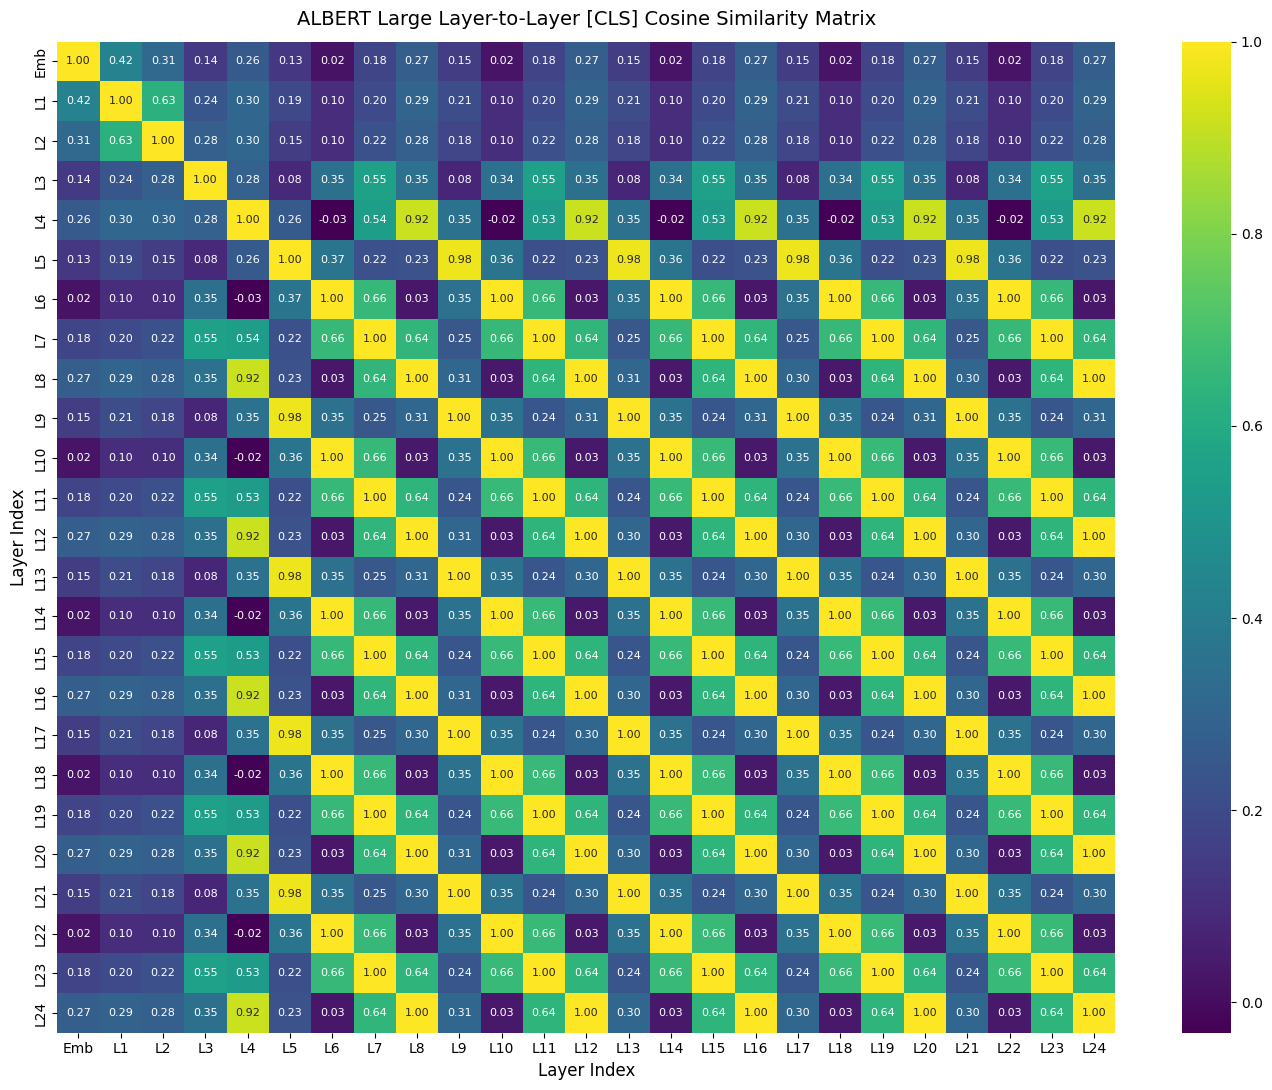

Layer cosine similarity heatmap saved to: ./output/images/layer_cosine_similarity.png


In [10]:
# ==============================================================================
# 10. Live Cell Layer Output Inspection & Activation Heatmap
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

print("Running forward pass on sample evaluation batch to inspect layer outputs...")
model.eval()

sample_batch = next(iter(val_loader))
with torch.no_grad():
    sample_out = model(
        input_ids=sample_batch["input_ids"].to(device),
        attention_mask=sample_batch["attention_mask"].to(device),
        node_feats=sample_batch["node_feats"].to(device),
        adj=sample_batch["adj"].to(device),
        return_layers=True
    )

# 1. Print formatted layer outputs directly to cell output
layer_summary_df = inspect_and_print_layer_outputs(sample_out)

# 2. Compute and plot layer-to-layer cosine similarity matrix for ALBERT
trans_reps = [l[:, 0, :].cpu().numpy() for l in sample_out["transformer_layers"]]  # [CLS] token per layer
num_layers = len(trans_reps)
sim_matrix = np.zeros((num_layers, num_layers))

for i in range(num_layers):
    for j in range(num_layers):
        dot = (trans_reps[i] * trans_reps[j]).sum(axis=-1)
        norm_i = np.linalg.norm(trans_reps[i], axis=-1)
        norm_j = np.linalg.norm(trans_reps[j], axis=-1)
        sim_matrix[i, j] = np.mean(dot / (norm_i * norm_j + 1e-9))

plt.figure(figsize=(14, 11))
sns.heatmap(
    sim_matrix,
    annot=(num_layers <= 25),
    fmt=".2f",
    cmap="viridis",
    annot_kws={"size": 8},
    xticklabels=["Emb"] + [f"L{k}" for k in range(1, num_layers)],
    yticklabels=["Emb"] + [f"L{k}" for k in range(1, num_layers)]
)
plt.title("ALBERT Large Layer-to-Layer [CLS] Cosine Similarity Matrix", fontsize=14, pad=12)
plt.xlabel("Layer Index", fontsize=12)
plt.ylabel("Layer Index", fontsize=12)
plt.tight_layout()
sim_fig_path = os.path.join(OUTPUT_DIR, "images", "layer_cosine_similarity.png")
plt.savefig(sim_fig_path, dpi=300)
plt.show()
print(f"Layer cosine similarity heatmap saved to: {sim_fig_path}")


In [11]:
# ==============================================================================
# 11. Test Set Evaluation & Performance Reports (Markdown + LaTeX)
# ==============================================================================
from sklearn.metrics import classification_report, confusion_matrix

print("Loading best model weights for final test evaluation...")
if os.path.exists(BEST_MODEL_PATH):
    model.load_state_dict(torch.load(BEST_MODEL_PATH))

model.eval()
all_prim_preds, all_prim_true = [], []
all_sub_preds, all_sub_true = [], []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        node_feats = batch["node_feats"].to(device)
        adj = batch["adj"].to(device)
        bsz = batch["batch_size"]
        
        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            logits_prim, logits_sub, _ = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                node_feats=node_feats,
                adj=adj
            )
            
        all_prim_preds.extend(logits_prim.argmax(dim=-1).cpu().numpy())
        all_prim_true.extend(batch["primary_targets"].numpy())
        all_sub_preds.extend(logits_sub.argmax(dim=-1).cpu().numpy())
        all_sub_true.extend(batch["subtype_targets"].numpy())

# Generate Classification Reports
prim_names = [PRIMARY_ID2LABEL[i] for i in range(len(PRIMARY_LABELS))]
sub_names = [SUBTYPE_ID2LABEL[i] for i in range(len(SUBTYPE_LABELS))]

# To this:
prim_labels_ids = list(range(len(prim_names)))
sub_labels_ids = list(range(len(sub_names)))

prim_report_dict = classification_report(
    all_prim_true, all_prim_preds, labels=prim_labels_ids, target_names=prim_names, output_dict=True, zero_division=0
)
sub_report_dict = classification_report(
    all_sub_true, all_sub_preds, labels=sub_labels_ids, target_names=sub_names, output_dict=True, zero_division=0
)


df_prim_report = pd.DataFrame(prim_report_dict).transpose()
df_sub_report = pd.DataFrame(sub_report_dict).transpose()

# Print formatted tables to cell output
print("\n" + "=" * 75)
print("             PRIMARY LABEL CLASSIFICATION REPORT (HAM / SPAM / PHISHING)")
print("=" * 75)
print(tabulate(df_prim_report, headers="keys", tablefmt="pipe", floatfmt=".4f"))

print("\n" + "=" * 75)
print("             PHISHING SUBTYPES CLASSIFICATION REPORT")
print("=" * 75)
print(tabulate(df_sub_report, headers="keys", tablefmt="pipe", floatfmt=".4f"))

# Persist to output tables and metrics
df_prim_report.to_csv(os.path.join(OUTPUT_DIR, "metrics", "classification_report_primary.csv"))
df_sub_report.to_csv(os.path.join(OUTPUT_DIR, "metrics", "classification_report_subtype.csv"))

# Save Markdown & LaTeX tables
with open(os.path.join(OUTPUT_DIR, "tables", "primary_report.md"), "w") as f:
    f.write("# Primary Classification Performance Table\n\n" + df_prim_report.to_markdown())
with open(os.path.join(OUTPUT_DIR, "tables", "primary_report.tex"), "w") as f:
    f.write(df_prim_report.to_latex())

with open(os.path.join(OUTPUT_DIR, "tables", "subtype_report.md"), "w") as f:
    f.write("# Phishing Subtypes Performance Table\n\n" + df_sub_report.to_markdown())
with open(os.path.join(OUTPUT_DIR, "tables", "subtype_report.tex"), "w") as f:
    f.write(df_sub_report.to_latex())

print("\nAll classification reports, Markdown tables, and LaTeX tables saved to ./output/tables/")


Loading best model weights for final test evaluation...

             PRIMARY LABEL CLASSIFICATION REPORT (HAM / SPAM / PHISHING)
|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| HAM          |      0.8381 |   0.9494 |     0.8903 | 3300.0000 |
| PHISHING     |      0.8711 |   0.9567 |     0.9119 | 3300.0000 |
| SPAM         |      0.8790 |   0.6761 |     0.7643 | 3300.0000 |
| accuracy     |      0.8607 |   0.8607 |     0.8607 |    0.8607 |
| macro avg    |      0.8628 |   0.8607 |     0.8555 | 9900.0000 |
| weighted avg |      0.8628 |   0.8607 |     0.8555 | 9900.0000 |

             PHISHING SUBTYPES CLASSIFICATION REPORT
|                       |   precision |   recall |   f1-score |   support |
|:----------------------|------------:|---------:|-----------:|----------:|
| NOT_PHISHING          |      0.9769 |   0.9294 |     0.9526 | 6600.0000 |
| BEC                   |      0.0000 |   0.0000 |  

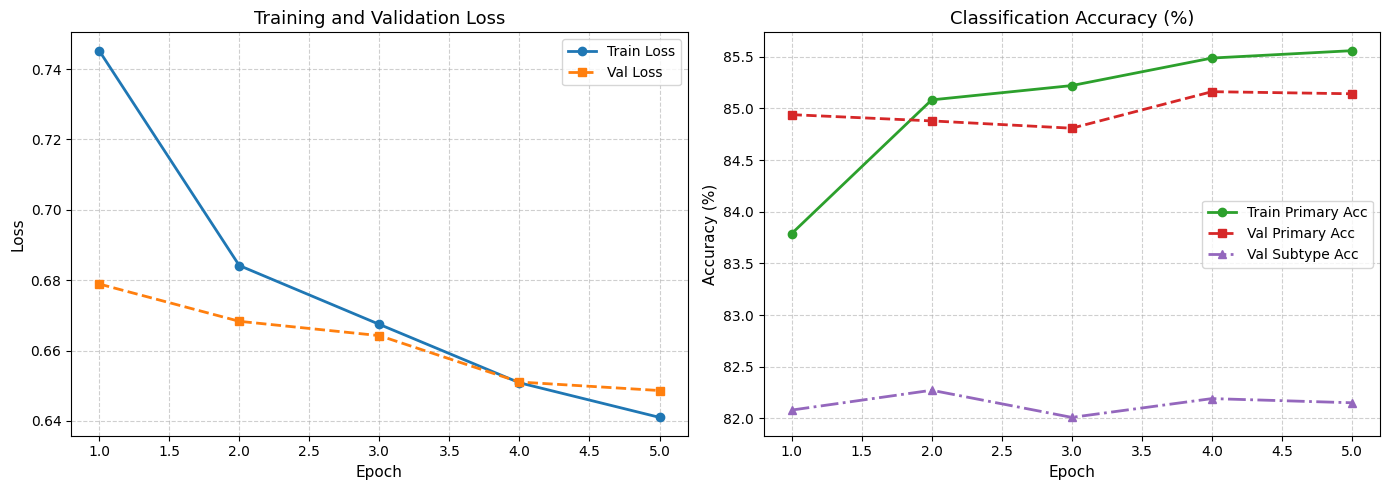

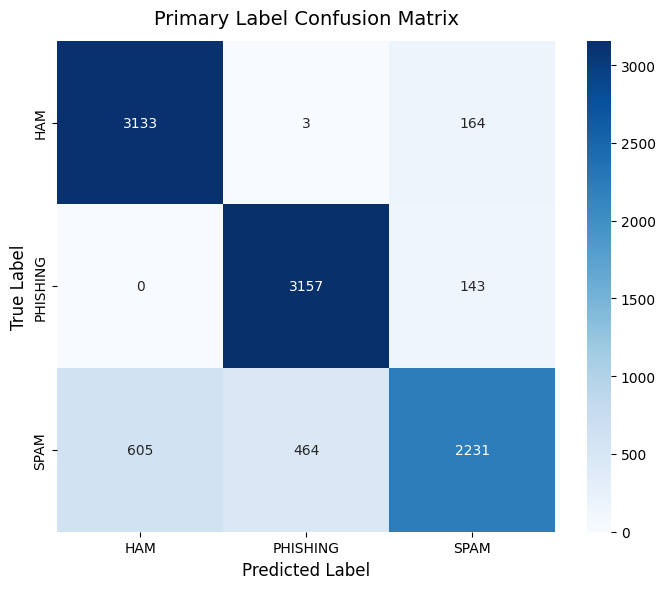

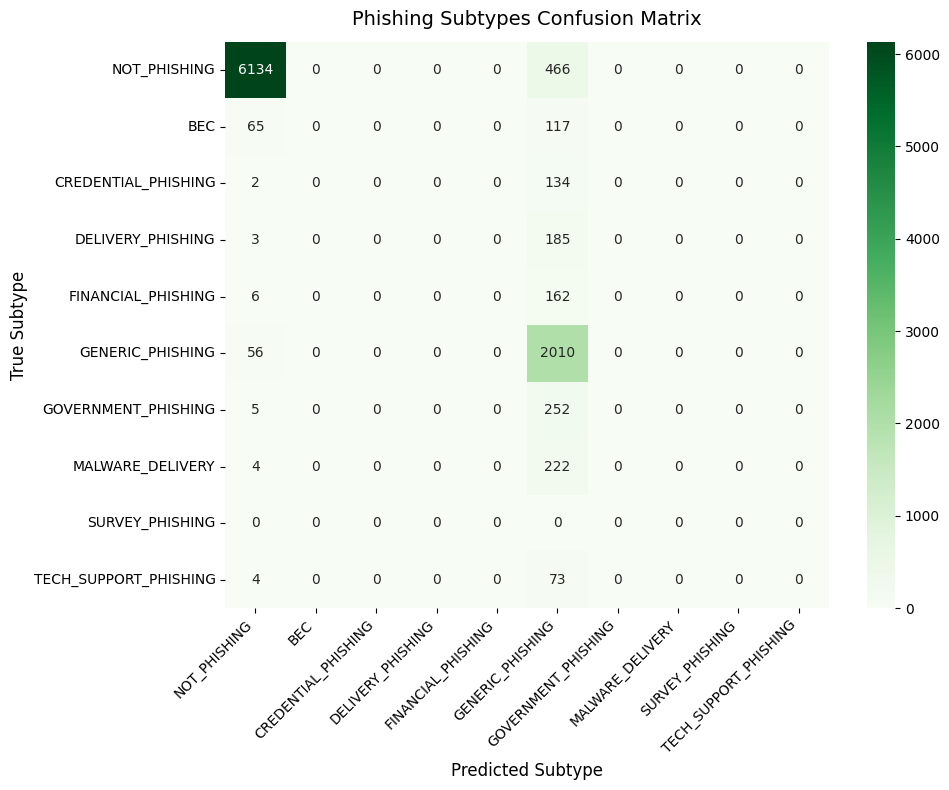

Visualizations saved to: ./output/images/


In [12]:
# ==============================================================================
# 12. Visualization Suite: Confusion Matrices & Training Curves
# ==============================================================================
# 1. Training & Validation Curves
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_df["epoch"], history_df["train_loss"], "o-", label="Train Loss", color="#1f77b4", linewidth=2)
axes[0].plot(history_df["epoch"], history_df["val_loss"], "s--", label="Val Loss", color="#ff7f0e", linewidth=2)
axes[0].set_title("Training and Validation Loss", fontsize=13)
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Loss", fontsize=11)
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["train_prim_acc"] * 100, "o-", label="Train Primary Acc", color="#2ca02c", linewidth=2)
axes[1].plot(history_df["epoch"], history_df["val_prim_acc"] * 100, "s--", label="Val Primary Acc", color="#d62728", linewidth=2)
axes[1].plot(history_df["epoch"], history_df["val_sub_acc"] * 100, "^-.", label="Val Subtype Acc", color="#9467bd", linewidth=2)
axes[1].set_title("Classification Accuracy (%)", fontsize=13)
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Accuracy (%)", fontsize=11)
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend()

plt.tight_layout()
curves_path = os.path.join(OUTPUT_DIR, "images", "loss_accuracy_curves.png")
plt.savefig(curves_path, dpi=300)
plt.show()

# 2. Primary Confusion Matrix
cm_prim = confusion_matrix(all_prim_true, all_prim_preds, labels=prim_labels_ids)
plt.figure(figsize=(7, 6))
sns.heatmap(cm_prim, annot=True, fmt="d", cmap="Blues", xticklabels=prim_names, yticklabels=prim_names)
plt.title("Primary Label Confusion Matrix", fontsize=14, pad=12)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.tight_layout()
cm_prim_path = os.path.join(OUTPUT_DIR, "images", "confusion_matrix_primary.png")
plt.savefig(cm_prim_path, dpi=300)
plt.show()

# 3. Phishing Subtypes Confusion Matrix
cm_sub = confusion_matrix(all_sub_true, all_sub_preds, labels=sub_labels_ids)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_sub, annot=True, fmt="d", cmap="Greens", xticklabels=sub_names, yticklabels=sub_names)
plt.title("Phishing Subtypes Confusion Matrix", fontsize=14, pad=12)
plt.xlabel("Predicted Subtype", fontsize=12)
plt.ylabel("True Subtype", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
cm_sub_path = os.path.join(OUTPUT_DIR, "images", "confusion_matrix_subtype.png")
plt.savefig(cm_sub_path, dpi=300)
plt.show()

print(f"Visualizations saved to: {OUTPUT_DIR}/images/")


Extracting text, graph, and fused embeddings for test subset...
Raw embeddings saved to ./output/embeddings/ (.npy files)
Computing t-SNE 2D projection on fused embeddings...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


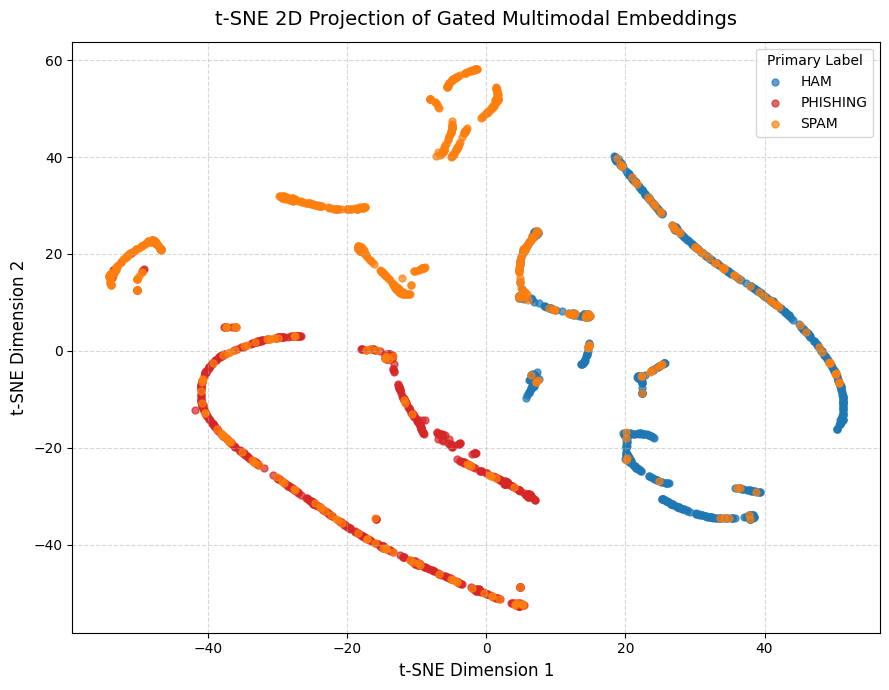

t-SNE projection plot saved to: ./output/images/tsne_fused_embeddings.png


In [13]:
# ==============================================================================
# 13. Embeddings Extraction & 2D Projection (t-SNE)
# ==============================================================================
from sklearn.manifold import TSNE

print("Extracting text, graph, and fused embeddings for test subset...")
model.eval()

all_z_text, all_z_graph, all_z_fused = [], [], []
sample_limit = 2000  # Extract up to 2000 samples for clean t-SNE visualization
count = 0

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        node_feats = batch["node_feats"].to(device)
        adj = batch["adj"].to(device)
        bsz = batch["batch_size"]
        
        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            out = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                node_feats=node_feats,
                adj=adj,
                return_layers=True
            )
            
        all_z_text.append(out["z_text"].cpu().numpy())
        all_z_graph.append(out["z_graph"].cpu().numpy())
        all_z_fused.append(out["z_fused"].cpu().numpy())
        count += bsz
        if count >= sample_limit:
            break

z_text_arr = np.concatenate(all_z_text, axis=0)[:sample_limit]
z_graph_arr = np.concatenate(all_z_graph, axis=0)[:sample_limit]
z_fused_arr = np.concatenate(all_z_fused, axis=0)[:sample_limit]
sub_labels = np.array(all_prim_true)[:sample_limit]

# Save Raw Embeddings to ./output/embeddings/
np.save(os.path.join(OUTPUT_DIR, "embeddings", "text_embeddings.npy"), z_text_arr)
np.save(os.path.join(OUTPUT_DIR, "embeddings", "graph_embeddings.npy"), z_graph_arr)
np.save(os.path.join(OUTPUT_DIR, "embeddings", "fused_embeddings.npy"), z_fused_arr)
print("Raw embeddings saved to ./output/embeddings/ (.npy files)")

# Run t-SNE Projection on Fused Embeddings
print("Computing t-SNE 2D projection on fused embeddings...")
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30, n_iter=1000)
z_fused_2d = tsne.fit_transform(z_fused_arr)

plt.figure(figsize=(9, 7))
colors = ["#1f77b4", "#d62728", "#ff7f0e"]
for idx, name in enumerate(prim_names):
    mask = (sub_labels == idx)
    plt.scatter(z_fused_2d[mask, 0], z_fused_2d[mask, 1], label=name, alpha=0.7, s=25, c=colors[idx])
    
plt.title("t-SNE 2D Projection of Gated Multimodal Embeddings", fontsize=14, pad=12)
plt.xlabel("t-SNE Dimension 1", fontsize=12)
plt.ylabel("t-SNE Dimension 2", fontsize=12)
plt.legend(title="Primary Label", frameon=True)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
tsne_fig_path = os.path.join(OUTPUT_DIR, "images", "tsne_fused_embeddings.png")
plt.savefig(tsne_fig_path, dpi=300)
plt.show()
print(f"t-SNE projection plot saved to: {tsne_fig_path}")


In [14]:
# ==============================================================================
# 14. Output Artifacts Verification & Zip Archive Packaging
# ==============================================================================
import shutil

print("\n" + "=" * 80)
print("                  GENERATED OUTPUT ARTIFACTS IN ./output/")
print("=" * 80)

total_bytes = 0
for root, dirs, files in os.walk(OUTPUT_DIR):
    level = root.replace(OUTPUT_DIR, "").count(os.sep)
    indent = " " * 4 * level
    folder_name = os.path.basename(root)
    print(f"{indent}📂 {folder_name}/")
    subindent = " " * 4 * (level + 1)
    for f in sorted(files):
        if f.endswith(".zip"):
            continue
        fp = os.path.join(root, f)
        sz = os.path.getsize(fp)
        total_bytes += sz
        if sz < 1024 * 1024:
            sz_str = f"{sz/1024:.1f} KB"
        else:
            sz_str = f"{sz/(1024*1024):.2f} MB"
        print(f"{subindent}📄 {f:38s} ({sz_str})")

print("=" * 80)
print(f"Total Output Artifacts Size: {total_bytes / (1024*1024):.2f} MB")

# Create Zip Archive for easy one-click download from Kaggle
ZIP_NAME = os.path.join(OUTPUT_DIR, "kaggle_run_artifacts")
print(f"Creating zip archive of all outputs at: {ZIP_NAME}.zip ...")
shutil.make_archive(ZIP_NAME, "zip", OUTPUT_DIR)
print(f"ZIP Archive Created: {ZIP_NAME}.zip ({os.path.getsize(ZIP_NAME + '.zip') / (1024*1024):.2f} MB)")
print(">>> Everything ready! You can download 'kaggle_run_artifacts.zip' directly from Kaggle.")



                  GENERATED OUTPUT ARTIFACTS IN ./output/
📂 output/
    📂 checkpoints/
        📄 best_model.pt                          (70.34 MB)
    📂 images/
        📄 confusion_matrix_primary.png           (108.4 KB)
        📄 confusion_matrix_subtype.png           (363.7 KB)
        📄 layer_cosine_similarity.png            (695.8 KB)
        📄 loss_accuracy_curves.png               (294.2 KB)
        📄 tsne_fused_embeddings.png              (412.6 KB)
    📂 metrics/
        📄 classification_report_primary.csv      (0.5 KB)
        📄 classification_report_subtype.csv      (0.7 KB)
        📄 label_mapping.json                     (0.4 KB)
        📄 training_history.csv                   (0.5 KB)
        📄 training_history.json                  (0.8 KB)
    📂 layer_outputs/
        📄 layer_states.pt                        (400.20 MB)
        📄 layer_summary.csv                      (2.6 KB)
    📂 embeddings/
        📄 fused_embeddings.npy                   (1.95 MB)
        📄 graph_

Generating Embedding Graph Connectivity Visualization...


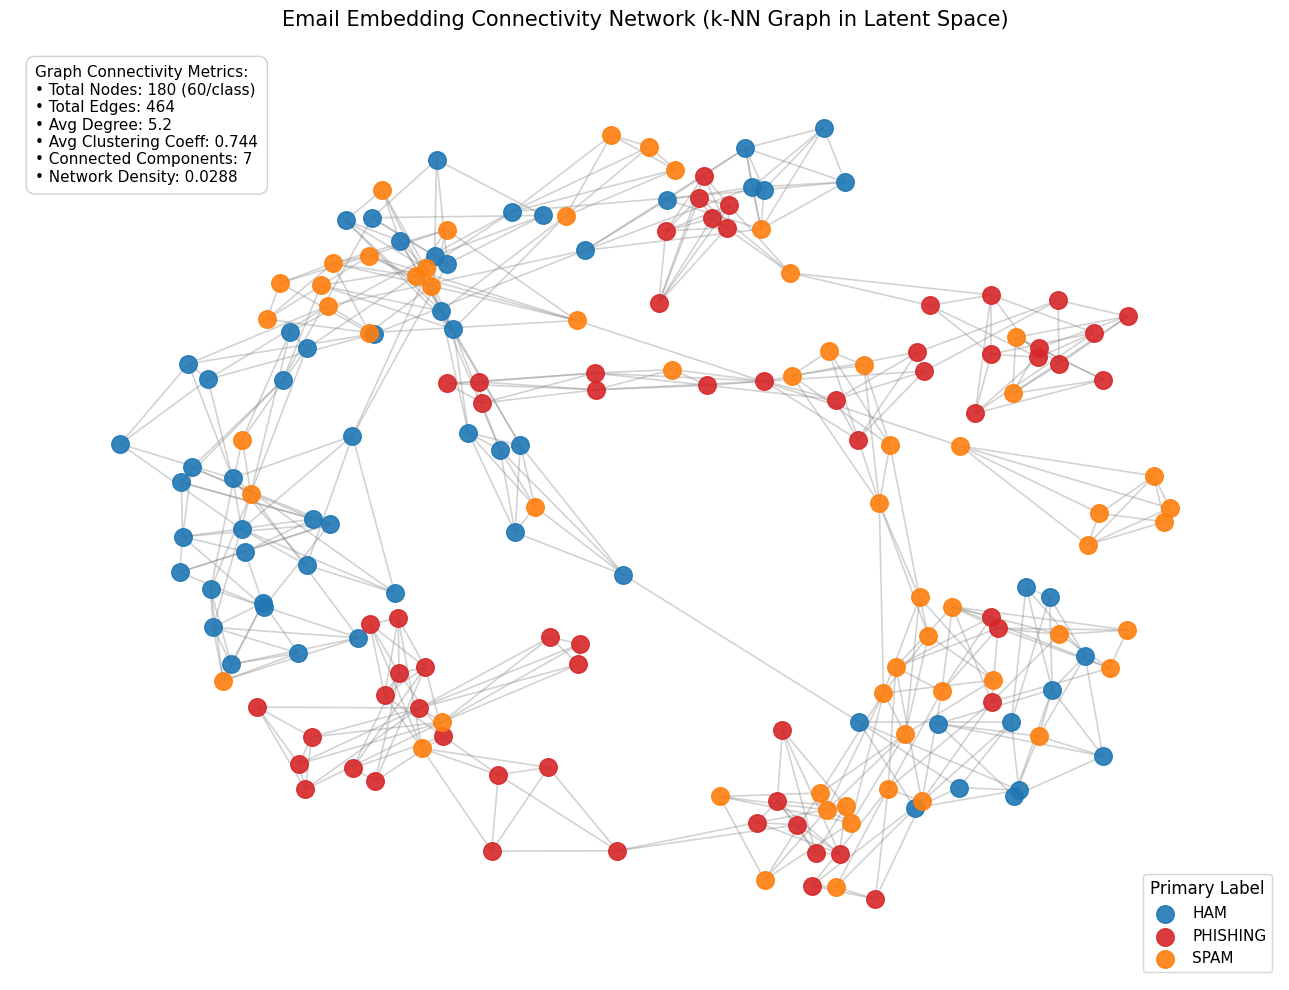

Graph connectivity visualization saved to: ./output/images/embedding_graph_connectivity.png


In [15]:
# ==============================================================================
# Cell: Embedding Graph Connectivity Visualization (k-NN Similarity Network)
# ==============================================================================
import os
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.neighbors import kneighbors_graph
from sklearn.metrics.pairwise import cosine_similarity

print("Generating Embedding Graph Connectivity Visualization...")

# 1. Load or retrieve embeddings & labels
if "z_fused_arr" in locals() and "sub_labels" in locals():
    embeddings = z_fused_arr
    labels = sub_labels
else:
    embeddings = np.load("./output/embeddings/fused_embeddings.npy")
    # If sub_labels not in memory, fallback to primary true labels from test
    labels = np.array(all_prim_true)[:len(embeddings)]

# 2. Sample 180 representative emails (60 per class for a crisp, readable graph)
np.random.seed(42)
sample_indices = []
for class_id in [0, 1, 2]:
    cls_idx = np.where(labels == class_id)[0]
    sample_indices.extend(np.random.choice(cls_idx, size=min(60, len(cls_idx)), replace=False))

sample_indices = np.array(sample_indices)
X_sub = embeddings[sample_indices]
y_sub = labels[sample_indices]

# 3. Build k-NN Connectivity Graph in Embedding Space (k=4 neighbors)
k = 4
adj_matrix = kneighbors_graph(X_sub, n_neighbors=k, mode='connectivity', metric='cosine', include_self=False)
G = nx.from_scipy_sparse_array(adj_matrix)

# 4. Map Node Attributes & Colors
class_names = {0: "HAM", 1: "PHISHING", 2: "SPAM"}
palette = {0: "#1f77b4", 1: "#d62728", 2: "#ff7f0e"}  # Blue: HAM, Red: PHISHING, Orange: SPAM

node_colors = [palette[y_sub[node]] for node in G.nodes()]
node_labels = [class_names[y_sub[node]] for node in G.nodes()]

# 5. Compute Graph Connectivity Metrics
clustering_coeff = nx.average_clustering(G)
num_components = nx.number_connected_components(G)
edge_density = nx.density(G)

# 6. Plot Network Topology using Force-Directed Layout
plt.figure(figsize=(13, 10))
pos = nx.spring_layout(G, k=0.35, iterations=60, seed=42)

# Draw Edges with subtle transparency
nx.draw_networkx_edges(G, pos, alpha=0.35, edge_color="gray", width=1.2)

# Draw Nodes grouped by class for clean legend
for class_id, class_name in class_names.items():
    idx_list = [i for i, y in enumerate(y_sub) if y == class_id]
    nx.draw_networkx_nodes(
        G, pos,
        nodelist=idx_list,
        node_color=palette[class_id],
        node_size=160,
        alpha=0.9,
        label=class_name
    )

# Add Annotation Box with Graph Statistics
stats_text = (
    f"Graph Connectivity Metrics:\n"
    f"• Total Nodes: {G.number_of_nodes()} (60/class)\n"
    f"• Total Edges: {G.number_of_edges()}\n"
    f"• Avg Degree: {2 * G.number_of_edges() / G.number_of_nodes():.1f}\n"
    f"• Avg Clustering Coeff: {clustering_coeff:.3f}\n"
    f"• Connected Components: {num_components}\n"
    f"• Network Density: {edge_density:.4f}"
)
plt.gca().text(
    0.02, 0.98, stats_text,
    transform=plt.gca().transAxes,
    fontsize=11,
    verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.6', facecolor='white', alpha=0.9, edgecolor='#ccc')
)

plt.title("Email Embedding Connectivity Network (k-NN Graph in Latent Space)", fontsize=15, pad=15)
plt.legend(title="Primary Label", loc="lower right", frameon=True, fontsize=11, title_fontsize=12)
plt.axis("off")
plt.tight_layout()

# Save image to output directory
save_path = "./output/images/embedding_graph_connectivity.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Graph connectivity visualization saved to: {save_path}")


In [16]:
# ==============================================================================
# Cell: Interactive Heterogeneous Graph (Email, Sender, Receiver, Domain, URL)
# ==============================================================================
import os
import json
import numpy as np
from IPython.display import display, HTML

print("Building Interactive Heterogeneous Email Graph (Email + Senders + Domains + URLs)...")

# 1. Retrieve dataset
if "test_df" in locals():
    sample_source = test_df.reset_index(drop=True)
elif "df" in locals():
    sample_source = df.reset_index(drop=True)
else:
    sample_source = pd.read_parquet("./augmented_66k.parquet")

# 2. Select 18 representative emails (6 HAM, 6 SPAM, 6 PHISHING with diverse subtypes)
# This creates a crisp, readable network of ~80-120 interconnected nodes
np.random.seed(42)
selected_indices = []
for p_label in ["HAM", "PHISHING", "SPAM"]:
    matches = sample_source[sample_source["primary_label"] == p_label].index.tolist()
    chosen = np.random.choice(matches, size=min(20, len(matches)), replace=False)
    selected_indices.extend(chosen)

sub_df = sample_source.iloc[selected_indices].reset_index(drop=True)

# 3. Build Heterogeneous Nodes & Edges
nodes_dict = {}
edges_list = []

# Color scheme by Node Type
NODE_STYLES = {
    "EMAIL_HAM": {"color": "#00b4d8", "shape": "diamond", "size": 18, "border": "#0077b6"},
    "EMAIL_PHISHING": {"color": "#ef233c", "shape": "diamond", "size": 18, "border": "#b91c1c"},
    "EMAIL_SPAM": {"color": "#ff9e00", "shape": "diamond", "size": 18, "border": "#d97706"},
    "SENDER": {"color": "#a855f7", "shape": "dot", "size": 14, "border": "#7e22ce"},
    "RECEIVER": {"color": "#10b981", "shape": "dot", "size": 14, "border": "#047857"},
    "DOMAIN": {"color": "#3b82f6", "shape": "hexagon", "size": 16, "border": "#1d4ed8"},
    "URL": {"color": "#facc15", "shape": "triangle", "size": 12, "border": "#ca8a04"}
}

def add_node(node_id, label, node_type, meta):
    if node_id not in nodes_dict:
        style = NODE_STYLES[node_type]
        nodes_dict[node_id] = {
            "id": node_id,
            "label": label[:25] + ("..." if len(label) > 25 else ""),
            "title": f"<b>[{node_type}]</b><br>{label}",
            "color": {
                "background": style["color"],
                "border": style["border"],
                "highlight": {"background": "#ffffff", "border": style["color"]}
            },
            "shape": style["shape"],
            "size": style["size"],
            "node_type": node_type,
            "meta": meta
        }

def add_edge(src, dst, label=""):
    edges_list.append({
        "from": src, "to": dst, "label": label,
        "color": {"color": "#475569", "opacity": 0.45},
        "width": 1.2,
        "font": {"size": 8, "color": "#64748b", "align": "middle"}
    })

for idx, row in sub_df.iterrows():
    p_label = str(row.get("primary_label", "UNKNOWN"))
    email_id = f"email_{idx}"
    sender = str(row.get("sender", f"sender_{idx}@domain.com")).strip()
    receiver = str(row.get("receiver", f"user_{idx}@corp.com")).strip()
    domain = str(row.get("sender_domain", "unknown.com")).strip()
    
    # 1. Email Message Node (Diamond)
    add_node(
        email_id,
        f"Email #{idx} [{p_label}]",
        f"EMAIL_{p_label}",
        {
            "category": "EMAIL",
            "subject": str(row.get("subject", "(No Subject)")),
            "primary_label": p_label,
            "phishing_subtype": str(row.get("phishing_subtype", "N/A")),
            "sender": sender,
            "receiver": receiver,
            "domain": domain,
            "has_spf": int(row.get("has_spf", 0)),
            "has_dkim": int(row.get("has_dkim", 0)),
            "num_urls": int(row.get("num_urls", 0)),
            "num_domains": int(row.get("num_domains", 0)),
            "body_preview": str(row.get("body_clean", ""))[:320].replace('"', '&quot;').replace('\n', ' ')
        }
    )
    
    # 2. Sender Node (Purple Circle)
    sender_id = f"sender_{sender}"
    add_node(sender_id, sender, "SENDER", {
        "category": "SENDER", "address": sender, "parent_domain": domain, "sent_email_id": email_id
    })
    add_edge(sender_id, email_id, "sends")
    
    # 3. Sender Domain Node (Blue Hexagon)
    domain_id = f"domain_{domain}"
    add_node(domain_id, domain, "DOMAIN", {
        "category": "DOMAIN", "domain_name": domain, "spf": int(row.get("has_spf", 0)), "dkim": int(row.get("has_dkim", 0))
    })
    add_edge(sender_id, domain_id, "belongs_to")
    
    # 4. Receiver Node (Green Circle)
    receiver_id = f"receiver_{receiver}"
    add_node(receiver_id, receiver, "RECEIVER", {
        "category": "RECEIVER", "address": receiver, "received_email_id": email_id
    })
    add_edge(email_id, receiver_id, "delivered_to")
    
    # 5. Destination Domains / URLs (Yellow Triangles)
    try:
        raw_doms = row.get("domains", "[]")
        dom_list = json.loads(raw_doms) if isinstance(raw_doms, str) and raw_doms.startswith("[") else [str(raw_doms)]
    except:
        dom_list = []
    
    for u_idx, u_dom in enumerate(dom_list[:4]):  # Cap at 4 links per email for visual clarity
        u_dom = str(u_dom).strip()
        if u_dom and u_dom != "None":
            url_id = f"url_{u_dom}"
            add_node(url_id, u_dom, "URL", {
                "category": "URL", "target_url": u_dom, "referenced_by": f"Email #{idx}"
            })
            add_edge(email_id, url_id, "links_to")

nodes_json = json.dumps(list(nodes_dict.values()))
edges_json = json.dumps(edges_list)

# 4. Generate Interactive HTML Page with Type-Aware Inspector
html_content = f"""<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <title>Heterogeneous Email Graph Inspector</title>
  <script type="text/javascript" src="https://unpkg.com/vis-network/standalone/umd/vis-network.min.js"></script>
  <link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700&display=swap" rel="stylesheet">
  <style>
    * {{ box-sizing: border-box; margin: 0; padding: 0; font-family: 'Inter', sans-serif; }}
    body {{ background: #0b0f19; color: #e2e8f0; display: flex; height: 100vh; overflow: hidden; }}
    
    #main-container {{ flex: 1; display: flex; flex-direction: column; position: relative; }}
    #header {{
      padding: 14px 24px; background: rgba(15, 23, 42, 0.85); backdrop-filter: blur(12px);
      border-bottom: 1px solid #1e293b; display: flex; justify-content: space-between; align-items: center; z-index: 10;
    }}
    .title-area h1 {{ font-size: 1.1rem; font-weight: 700; color: #f8fafc; display: flex; align-items: center; gap: 8px; }}
    .title-area p {{ font-size: 0.78rem; color: #94a3b8; }}
    
    .controls {{ display: flex; gap: 8px; align-items: center; }}
    .btn {{
      padding: 6px 12px; border-radius: 6px; font-size: 0.78rem; font-weight: 600; cursor: pointer;
      border: 1px solid #334155; background: #1e293b; color: #cbd5e1; transition: all 0.2s;
    }}
    .btn:hover {{ background: #334155; color: #fff; }}
    
    .legend {{ display: flex; gap: 14px; margin-left: 12px; font-size: 0.78rem; align-items: center; }}
    .legend-item {{ display: flex; align-items: center; gap: 6px; }}
    .shape-icon {{ display: inline-block; }}
    
    #network-canvas {{ flex: 1; width: 100%; height: 100%; background: radial-gradient(circle at center, #1e293b 0%, #090d16 100%); }}

    #sidebar {{
      width: 420px; background: #111827; border-left: 1px solid #1f2937; padding: 24px;
      display: flex; flex-direction: column; overflow-y: auto; box-shadow: -8px 0 24px rgba(0,0,0,0.5);
    }}
    .sidebar-header {{ margin-bottom: 16px; padding-bottom: 12px; border-bottom: 1px solid #1f2937; }}
    .sidebar-header h2 {{ font-size: 1.1rem; font-weight: 700; color: #f8fafc; }}
    .sidebar-header p {{ font-size: 0.78rem; color: #94a3b8; }}
    
    .badge {{
      display: inline-block; padding: 4px 10px; border-radius: 999px; font-size: 0.72rem; font-weight: 700;
      letter-spacing: 0.5px; text-transform: uppercase; margin-bottom: 12px;
    }}
    .badge-EMAIL_HAM {{ background: rgba(0, 180, 216, 0.2); color: #00b4d8; border: 1px solid #00b4d8; }}
    .badge-EMAIL_PHISHING {{ background: rgba(239, 35, 60, 0.2); color: #ef233c; border: 1px solid #ef233c; }}
    .badge-EMAIL_SPAM {{ background: rgba(255, 158, 0, 0.2); color: #ff9e00; border: 1px solid #ff9e00; }}
    .badge-SENDER {{ background: rgba(168, 85, 247, 0.2); color: #c084fc; border: 1px solid #a855f7; }}
    .badge-RECEIVER {{ background: rgba(16, 185, 129, 0.2); color: #34d399; border: 1px solid #10b981; }}
    .badge-DOMAIN {{ background: rgba(59, 130, 246, 0.2); color: #60a5fa; border: 1px solid #3b82f6; }}
    .badge-URL {{ background: rgba(250, 204, 21, 0.2); color: #fde047; border: 1px solid #facc15; }}
    
    .field-group {{ margin-bottom: 14px; }}
    .field-label {{ font-size: 0.72rem; font-weight: 600; text-transform: uppercase; color: #64748b; margin-bottom: 4px; }}
    .field-val {{ font-size: 0.85rem; color: #e2e8f0; word-break: break-all; background: #0b0f19; padding: 8px 10px; border-radius: 6px; border: 1px solid #1f2937; }}
    
    .security-grid {{ display: grid; grid-template-columns: 1fr 1fr; gap: 8px; margin-bottom: 14px; }}
    .sec-card {{ background: #0b0f19; padding: 8px 10px; border-radius: 6px; border: 1px solid #1f2937; text-align: center; }}
    .sec-title {{ font-size: 0.7rem; color: #64748b; font-weight: 600; }}
    .sec-status {{ font-size: 0.85rem; font-weight: 700; margin-top: 2px; }}
    .pass {{ color: #10b981; }}
    .fail {{ color: #ef4444; }}
    
    .body-preview {{ font-size: 0.8rem; color: #cbd5e1; line-height: 1.5; max-height: 180px; overflow-y: auto; white-space: pre-wrap; }}
    #placeholder-msg {{ color: #64748b; font-size: 0.9rem; text-align: center; margin-top: 100px; line-height: 1.6; }}
  </style>
</head>
<body>

  <div id="main-container">
    <div id="header">
      <div class="title-area">
        <h1>🕸️ Heterogeneous Email Relational Graph</h1>
        <p>Entities: Email Messages, Senders, Receivers, Domains & Referenced URLs</p>
      </div>
      <div class="controls">
        <button class="btn" onclick="network.fit({{animation: true}})">Zoom to Fit</button>
        <button class="btn" onclick="togglePhysics()">Toggle Physics</button>
        <div class="legend">
          <div class="legend-item"><span style="color:#00b4d8;">◆</span> HAM</div>
          <div class="legend-item"><span style="color:#ef233c;">◆</span> PHISHING</div>
          <div class="legend-item"><span style="color:#ff9e00;">◆</span> SPAM</div>
          <div class="legend-item"><span style="color:#a855f7;">●</span> Sender</div>
          <div class="legend-item"><span style="color:#10b981;">●</span> Receiver</div>
          <div class="legend-item"><span style="color:#3b82f6;">⬡</span> Domain</div>
          <div class="legend-item"><span style="color:#facc15;">▲</span> URL</div>
        </div>
      </div>
    </div>
    <div id="network-canvas"></div>
  </div>

  <div id="sidebar">
    <div class="sidebar-header">
      <h2>Entity Details Inspector</h2>
      <p>Click any node in the graph to view entity details</p>
    </div>
    <div id="inspector-content">
      <div id="placeholder-msg">
        👆 <b>No Node Selected</b><br>
        Click on any Email, Sender, Receiver, Domain, or URL node in the graph to inspect its properties.
      </div>
    </div>
  </div>

  <script>
    const nodes = new vis.DataSet({nodes_json});
    const edges = new vis.DataSet({edges_json});

    const container = document.getElementById('network-canvas');
    const data = {{ nodes: nodes, edges: edges }};
    const options = {{
      nodes: {{
        borderWidth: 2,
        shadow: true,
        font: {{ color: '#e2e8f0', size: 10, face: 'Inter' }}
      }},
      edges: {{
        arrows: {{ to: {{ enabled: true, scaleFactor: 0.5 }} }},
        smooth: {{ type: 'cubicBezier', roundness: 0.2 }},
        shadow: false
      }},
      physics: {{
        forceAtlas2Based: {{
          gravitationalConstant: -70,
          centralGravity: 0.02,
          springLength: 80,
          springConstant: 0.06
        }},
        solver: 'forceAtlas2Based',
        stabilization: {{ iterations: 150 }}
      }},
      interaction: {{ hover: true, tooltipDelay: 80 }}
    }};

    const network = new vis.Network(container, data, options);
    let physicsActive = true;

    function togglePhysics() {{
      physicsActive = !physicsActive;
      network.setOptions({{ physics: {{ enabled: physicsActive }} }});
    }}

    network.on("click", function (params) {{
      if (params.nodes.length > 0) {{
        const nodeId = params.nodes[0];
        const node = nodes.get(nodeId);
        const meta = node.meta;
        let contentHtml = '';

        if (meta.category === 'EMAIL') {{
          const spfClass = meta.has_spf === 1 ? 'pass' : 'fail';
          const spfText = meta.has_spf === 1 ? 'PASS ✓' : 'FAIL ✗';
          const dkimClass = meta.has_dkim === 1 ? 'pass' : 'fail';
          const dkimText = meta.has_dkim === 1 ? 'PASS ✓' : 'FAIL ✗';

          contentHtml = `
            <span class="badge badge-${{node.node_type}}">${{meta.primary_label}} EMAIL</span>
            <div class="field-group">
              <div class="field-label">Phishing Subtype</div>
              <div class="field-val" style="color:#38bdf8; font-weight:600;">${{meta.phishing_subtype}}</div>
            </div>
            <div class="field-group">
              <div class="field-label">Subject</div>
              <div class="field-val" style="font-weight:600;">${{meta.subject}}</div>
            </div>
            <div class="field-group">
              <div class="field-label">Sender</div>
              <div class="field-val">${{meta.sender}}</div>
            </div>
            <div class="field-group">
              <div class="field-label">Receiver</div>
              <div class="field-val">${{meta.receiver}}</div>
            </div>
            <div class="security-grid">
              <div class="sec-card"><div class="sec-title">SPF</div><div class="sec-status ${{spfClass}}">${{spfText}}</div></div>
              <div class="sec-card"><div class="sec-title">DKIM</div><div class="sec-status ${{dkimClass}}">${{dkimText}}</div></div>
              <div class="sec-card"><div class="sec-title">URLs</div><div class="sec-status">${{meta.num_urls}}</div></div>
              <div class="sec-card"><div class="sec-title">Domains</div><div class="sec-status">${{meta.num_domains}}</div></div>
            </div>
            <div class="field-group">
              <div class="field-label">Clean Body Preview</div>
              <div class="field-val body-preview">${{meta.body_preview}}...</div>
            </div>
          `;
        }} else if (meta.category === 'SENDER') {{
          contentHtml = `
            <span class="badge badge-SENDER">SENDER ENTITY</span>
            <div class="field-group">
              <div class="field-label">Email Address</div>
              <div class="field-val" style="font-weight:600; color:#c084fc;">${{meta.address}}</div>
            </div>
            <div class="field-group">
              <div class="field-label">Parent Domain</div>
              <div class="field-val">${{meta.parent_domain}}</div>
            </div>
          `;
        }} else if (meta.category === 'RECEIVER') {{
          contentHtml = `
            <span class="badge badge-RECEIVER">RECEIVER ENTITY</span>
            <div class="field-group">
              <div class="field-label">Email Address</div>
              <div class="field-val" style="font-weight:600; color:#34d399;">${{meta.address}}</div>
            </div>
          `;
        }} else if (meta.category === 'DOMAIN') {{
          const spfText = meta.spf === 1 ? 'PASS ✓' : 'FAIL ✗';
          const spfClass = meta.spf === 1 ? 'pass' : 'fail';
          contentHtml = `
            <span class="badge badge-DOMAIN">DOMAIN ENTITY</span>
            <div class="field-group">
              <div class="field-label">Domain Name</div>
              <div class="field-val" style="font-weight:600; color:#60a5fa;">${{meta.domain_name}}</div>
            </div>
            <div class="security-grid">
              <div class="sec-card"><div class="sec-title">SPF Policy</div><div class="sec-status ${{spfClass}}">${{spfText}}</div></div>
              <div class="sec-card"><div class="sec-title">DKIM Signed</div><div class="sec-status ${{spfClass}}">${{spfText}}</div></div>
            </div>
          `;
        }} else if (meta.category === 'URL') {{
          contentHtml = `
            <span class="badge badge-URL">DESTINATION URL / DOMAIN</span>
            <div class="field-group">
              <div class="field-label">Hyperlink Target</div>
              <div class="field-val" style="font-weight:600; color:#facc15;">${{meta.target_url}}</div>
            </div>
            <div class="field-group">
              <div class="field-label">Embedded in</div>
              <div class="field-val">${{meta.referenced_by}}</div>
            </div>
          `;
        }}

        document.getElementById('inspector-content').innerHTML = contentHtml;
      }}
    }});
  </script>
</body>
</html>
"""

# Save to output directory
HETERO_HTML_PATH = "./output/interactive_heterogeneous_graph.html"
with open(HETERO_HTML_PATH, "w", encoding="utf-8") as f:
    f.write(html_content)

print(f"Heterogeneous Graph saved to: {HETERO_HTML_PATH}")

# Display Clickable Link and Embedded Frame
display(HTML(f"""
<div style="background:#0f172a; padding:16px 20px; border-radius:10px; border:1px solid #334155; margin-bottom:12px; display:flex; justify-content:space-between; align-items:center;">
  <div>
    <h3 style="color:#f8fafc; margin:0 0 4px 0; font-size:1.05rem;">🕸️ Heterogeneous Email Graph Generated!</h3>
    <p style="color:#94a3b8; margin:0; font-size:0.85rem;">Interactive network with Email Messages, Senders, Receivers, Domains, and Destination URLs.</p>
  </div>
  <a href="{HETERO_HTML_PATH}" target="_blank" style="background:#8b5cf6; color:#ffffff; padding:10px 18px; border-radius:8px; text-decoration:none; font-weight:600; font-size:0.9rem; box-shadow:0 4px 12px rgba(139,92,246,0.3);">
    🚀 Open Fullscreen Graph
  </a>
</div>
<iframe src="{HETERO_HTML_PATH}" width="100%" height="700px" style="border:1px solid #1e293b; border-radius:12px; box-shadow:0 8px 30px rgba(0,0,0,0.5);"></iframe>
"""))


Building Interactive Heterogeneous Email Graph (Email + Senders + Domains + URLs)...
Heterogeneous Graph saved to: ./output/interactive_heterogeneous_graph.html


In [17]:
# ==============================================================================
# Interactive ALBERT + GIN Email Classification Dashboard
# ==============================================================================
import re
import urllib.parse
import ipywidgets as widgets
from IPython.display import display, HTML
import torch
import torch.nn.functional as F
import numpy as np

# 1. Verify Model & Tokenizer Availability
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

if "model" not in globals():
    print("Loading model from checkpoint...")
    model = AlbertGINClassifier(albert_model_name="albert-large-v2", num_primary=3, num_subtypes=10)
    checkpoint_path = "./output/checkpoints/best_model.pt"
    if os.path.exists(checkpoint_path):
        state_dict = torch.load(checkpoint_path, map_location=device)
        # Handle DataParallel prefix if present
        clean_state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
        model.load_state_dict(clean_state_dict)
        print(f"Loaded weights from {checkpoint_path}")
    model.to(device)

model.eval()

if "tokenizer" not in globals():
    from transformers import AutoTokenizer
    tokenizer = AutoTokenizer.from_pretrained("albert-large-v2")

PRIMARY_MAP = {0: "HAM", 1: "PHISHING", 2: "SPAM"}
SUBTYPE_MAP = {
    0: "NOT_PHISHING", 1: "BEC", 2: "CREDENTIAL_PHISHING", 3: "DELIVERY_PHISHING",
    4: "FINANCIAL_PHISHING", 5: "GENERIC_PHISHING", 6: "GOVERNMENT_PHISHING",
    7: "MALWARE_DELIVERY", 8: "SURVEY_PHISHING", 9: "TECH_SUPPORT_PHISHING"
}

# 2. Entity & Graph Feature Extractor
def extract_email_features(sender, receiver, subject, body, has_spf, has_dkim):
    # Extract URLs
    url_pattern = r'https?://[^\s<>"]+|www\.[^\s<>"]+'
    urls = re.findall(url_pattern, body)
    
    # Extract Domains
    domains = set()
    if "@" in sender:
        domains.add(sender.split("@")[-1].strip().lower())
    for u in urls:
        try:
            netloc = urllib.parse.urlparse(u).netloc
            if netloc:
                domains.add(netloc.lower())
        except:
            pass
    domain_list = list(domains)[:10]

    # Build GIN Graph (14 nodes, 16 features)
    MAX_NODES = 14
    features = np.zeros((MAX_NODES, 16), dtype=np.float32)
    adj = np.zeros((MAX_NODES, MAX_NODES), dtype=np.float32)

    # Node 0: Sender
    features[0, 0] = 1.0
    features[0, 4] = 1.0 if has_spf else 0.0
    features[0, 5] = 1.0 if has_dkim else 0.0
    features[0, 6] = min(len(urls) / 10.0, 1.0)
    features[0, 7] = min(len(domain_list) / 10.0, 1.0)
    features[0, 8] = min(len(body) / 5000.0, 1.0)

    # Node 1: Receiver
    features[1, 1] = 1.0
    features[1, 8] = features[0, 8]

    # Node 2: Sender Domain
    features[2, 2] = 1.0
    features[2, 4] = features[0, 4]
    features[2, 5] = features[0, 5]

    # Node 3..K: Destination Domains
    for i, dom in enumerate(domain_list):
        idx = 3 + i
        if idx >= MAX_NODES:
            break
        features[idx, 3] = 1.0
        features[idx, 6] = 1.0 / (i + 1)
        adj[1, idx] = 1.0
        adj[idx, 1] = 1.0

    # Core bidirectional links
    adj[0, 2] = 1.0; adj[2, 0] = 1.0
    adj[0, 1] = 1.0; adj[1, 0] = 1.0

    return features, adj, urls, domain_list

# 3. Presets for Quick Testing
PRESETS = {
    "Select a preset email...": {"sender": "", "receiver": "", "subject": "", "body": "", "spf": False, "dkim": False},
    "🚨 Credential Phishing (PayPal Spoof)": {
        "sender": "service-security@paypa1-update-center.com",
        "receiver": "user@corporate-network.com",
        "subject": "URGENT: Your account has been suspended! Verify your credentials",
        "body": "Dear customer, We detected unauthorized attempts to access your account. Your account is temporarily locked. Please log in immediately at http://login-paypa1-account-security.com/verification to re-activate your profile. Failure to do so within 24 hours will result in permanent suspension.",
        "spf": False,
        "dkim": False
    },
    "💼 Business Email Compromise (BEC / Wire Transfer)": {
        "sender": "ceo-execoffice@company-partner-hq.org",
        "receiver": "cfo@company.com",
        "subject": "Confidential: Immediate Wire Transfer Required for Project Omega",
        "body": "Hi, I am currently in a board meeting and cannot take calls. We need to execute an urgent invoice payment of $48,500 to finalize the supplier acquisition. Please wire the funds to the account details attached in the link: http://wire-transfer-portal.finance-partner.net. Confirm once completed.",
        "spf": False,
        "dkim": False
    },
    "📢 Commercial Spam": {
        "sender": "exclusive-deals@bestmarketingoffers24.biz",
        "receiver": "user@gmail.com",
        "subject": "Claim Your 85% Discount Voucher - Limited Quantity Available!",
        "body": "Congratulations! You have been selected for our VIP seasonal clearance. Get up to 85% off all electronics, luxury watches, and smart gear. Click here to claim your coupon code now: http://deals.bestmarketingoffers24.biz/voucher-claim. Unsubscribe at http://optout.marketing24.biz",
        "spf": True,
        "dkim": False
    },
    "✅ Legitimate Ham (Project Sync)": {
        "sender": "sarah.jenkins@company.com",
        "receiver": "alex.morgan@company.com",
        "subject": "Sprint Planning & Architecture Sync - Tomorrow 10:00 AM",
        "body": "Hi Alex, Just following up on the quarterly roadmap. I have reviewed the pull request for the API gateway integration and left a few minor comments. Let's sync tomorrow at 10 AM to discuss the database migration plan. The agenda document is on Google Drive: https://docs.google.com/document/d/1a2b3c4d5e",
        "spf": True,
        "dkim": True
    }
}

# 4. Construct UI Controls
style = {'description_width': '120px'}
layout_full = widgets.Layout(width='100%', margin='4px 0')

preset_dropdown = widgets.Dropdown(
    options=list(PRESETS.keys()),
    description='⚡ Quick Presets:',
    style=style,
    layout=layout_full
)

sender_txt = widgets.Text(
    value="service-security@paypa1-update-center.com",
    placeholder="e.g. support@secure-bank.com",
    description="Sender Email:",
    style=style,
    layout=layout_full
)

receiver_txt = widgets.Text(
    value="user@company.com",
    placeholder="e.g. employee@company.com",
    description="Receiver Email:",
    style=style,
    layout=layout_full
)

subject_txt = widgets.Text(
    value="URGENT: Your account has been suspended! Verify your credentials",
    placeholder="e.g. Urgent Notice",
    description="Subject:",
    style=style,
    layout=layout_full
)

body_txt = widgets.Textarea(
    value="Dear customer, We detected unauthorized attempts to access your account. Please log in immediately at http://login-paypa1-account-security.com/verification to re-activate your profile.",
    placeholder="Paste email message body here...",
    description="Body:",
    rows=5,
    style=style,
    layout=layout_full
)

spf_chk = widgets.Checkbox(value=False, description='SPF Authenticated', indent=False)
dkim_chk = widgets.Checkbox(value=False, description='DKIM Authenticated', indent=False)
auth_box = widgets.HBox([widgets.Label("Authentication:", layout=widgets.Layout(width="120px")), spf_chk, dkim_chk])

classify_btn = widgets.Button(
    description="🛡️  Classify Email with ALBERT + GIN",
    button_style="danger",
    layout=widgets.Layout(width='100%', height='48px', margin='12px 0', border='none')
)

output_view = widgets.Output()

def on_preset_change(change):
    p = PRESETS[change['new']]
    if p["sender"]:
        sender_txt.value = p["sender"]
        receiver_txt.value = p["receiver"]
        subject_txt.value = p["subject"]
        body_txt.value = p["body"]
        spf_chk.value = p["spf"]
        dkim_chk.value = p["dkim"]

preset_dropdown.observe(on_preset_change, names='value')

# 5. Prediction & Rendering Callback
def classify_email(b):
    output_view.clear_output()
    with output_view:
        sender = sender_txt.value.strip()
        receiver = receiver_txt.value.strip()
        subject = subject_txt.value.strip()
        body = body_txt.value.strip()
        spf = spf_chk.value
        dkim = dkim_chk.value

        if not subject and not body:
            print("Please enter a subject or email body to classify.")
            return

        # Prepare Text
        full_text = f"Subject: {subject} | Message: {body}"
        tokens = tokenizer(
            full_text,
            max_length=256,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )
        
        # Prepare Graph
        node_feats, adj, urls, domain_list = extract_email_features(sender, receiver, subject, body, spf, dkim)
        node_feats_t = torch.from_numpy(node_feats).unsqueeze(0).to(device)
        adj_t = torch.from_numpy(adj).unsqueeze(0).to(device)
        input_ids = tokens["input_ids"].to(device)
        attention_mask = tokens["attention_mask"].to(device)

        # Forward Pass
        with torch.no_grad():
            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                logits_prim, logits_sub, z_fused = model(input_ids, attention_mask, node_feats_t, adj_t)

            probs_prim = F.softmax(logits_prim, dim=-1).cpu().numpy()[0]
            probs_sub = F.softmax(logits_sub, dim=-1).cpu().numpy()[0]

        pred_prim_id = int(np.argmax(probs_prim))
        pred_prim_label = PRIMARY_MAP[pred_prim_id]
        pred_sub_id = int(np.argmax(probs_sub))
        pred_sub_label = SUBTYPE_MAP[pred_sub_id]

        # Theme styling based on verdict
        theme_color = "#ef4444" if pred_prim_label == "PHISHING" else ("#f59e0b" if pred_prim_label == "SPAM" else "#10b981")
        badge_icon = "⚠️" if pred_prim_label == "PHISHING" else ("📬" if pred_prim_label == "SPAM" else "✅")

        # HTML Result Card
        html_code = f"""
        <div style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; 
                    background: #0f172a; border-radius: 16px; padding: 24px; color: #f8fafc; margin-top: 16px; 
                    box-shadow: 0 10px 30px -10px rgba(0,0,0,0.5); border: 1px solid #1e293b;">
            
            <!-- Result Header -->
            <div style="display: flex; justify-content: space-between; align-items: center; border-bottom: 1px solid #1e293b; padding-bottom: 16px;">
                <div>
                    <div style="font-size: 12px; color: #94a3b8; text-transform: uppercase; letter-spacing: 0.08em; font-weight: 600;">Classification Result</div>
                    <div style="font-size: 28px; font-weight: 800; color: {theme_color}; display: flex; align-items: center; gap: 8px; margin-top: 4px;">
                        <span>{badge_icon}</span> {pred_prim_label}
                        <span style="font-size: 16px; background: rgba(255,255,255,0.1); padding: 4px 10px; border-radius: 8px; color: #f8fafc;">
                            {probs_prim[pred_prim_id]*100:.1f}% Confidence
                        </span>
                    </div>
                </div>
                {f'''
                <div style="text-align: right;">
                    <div style="font-size: 11px; color: #94a3b8; text-transform: uppercase; letter-spacing: 0.08em;">Detected Threat Vector</div>
                    <div style="font-size: 16px; font-weight: 700; color: #f43f5e; background: rgba(244,63,94,0.15); 
                                border: 1px solid #f43f5e; padding: 6px 14px; border-radius: 9999px; margin-top: 4px;">
                        {pred_sub_label}
                    </div>
                </div>''' if pred_prim_label == "PHISHING" else ""}
            </div>

            <!-- Probability Distribution Bars -->
            <div style="margin-top: 20px;">
                <div style="font-size: 13px; font-weight: 600; color: #cbd5e1; margin-bottom: 10px;">Primary Class Confidence:</div>
                <div style="display: grid; grid-template-columns: 90px 1fr 60px; align-items: center; gap: 10px; margin-bottom: 8px;">
                    <span style="font-size: 12px; color: #10b981; font-weight: 600;">HAM:</span>
                    <div style="background: #1e293b; height: 10px; border-radius: 5px; overflow: hidden;">
                        <div style="background: linear-gradient(90deg, #10b981, #34d399); width: {probs_prim[0]*100:.1f}%; height: 100%;"></div>
                    </div>
                    <span style="font-size: 12px; color: #94a3b8; text-align: right;">{probs_prim[0]*100:.1f}%</span>
                </div>
                <div style="display: grid; grid-template-columns: 90px 1fr 60px; align-items: center; gap: 10px; margin-bottom: 8px;">
                    <span style="font-size: 12px; color: #ef4444; font-weight: 600;">PHISHING:</span>
                    <div style="background: #1e293b; height: 10px; border-radius: 5px; overflow: hidden;">
                        <div style="background: linear-gradient(90deg, #ef4444, #f87171); width: {probs_prim[1]*100:.1f}%; height: 100%;"></div>
                    </div>
                    <span style="font-size: 12px; color: #94a3b8; text-align: right;">{probs_prim[1]*100:.1f}%</span>
                </div>
                <div style="display: grid; grid-template-columns: 90px 1fr 60px; align-items: center; gap: 10px;">
                    <span style="font-size: 12px; color: #f59e0b; font-weight: 600;">SPAM:</span>
                    <div style="background: #1e293b; height: 10px; border-radius: 5px; overflow: hidden;">
                        <div style="background: linear-gradient(90deg, #f59e0b, #fbbf24); width: {probs_prim[2]*100:.1f}%; height: 100%;"></div>
                    </div>
                    <span style="font-size: 12px; color: #94a3b8; text-align: right;">{probs_prim[2]*100:.1f}%</span>
                </div>
            </div>

            <!-- Extracted Entity Analysis -->
            <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 16px; margin-top: 20px; background: #1e293b; padding: 14px; border-radius: 12px;">
                <div>
                    <div style="font-size: 11px; color: #94a3b8; text-transform: uppercase;">Sender & Authentication</div>
                    <div style="font-size: 13px; color: #f8fafc; font-weight: 600; margin-top: 4px; word-break: break-all;">{sender or 'Unknown'}</div>
                    <div style="font-size: 11px; color: #cbd5e1; margin-top: 4px;">
                        SPF: <span style="color: {'#10b981' if spf else '#ef4444'}; font-weight: bold;">{'PASS' if spf else 'FAIL'}</span> | 
                        DKIM: <span style="color: {'#10b981' if dkim else '#ef4444'}; font-weight: bold;">{'PASS' if dkim else 'FAIL'}</span>
                    </div>
                </div>
                <div>
                    <div style="font-size: 11px; color: #94a3b8; text-transform: uppercase;">Extracted Hyperlinks ({len(urls)})</div>
                    <div style="font-size: 12px; color: #38bdf8; margin-top: 4px; max-height: 50px; overflow-y: auto; word-break: break-all;">
                        {('<br>'.join([f"🔗 {u}" for u in urls])) if urls else '<span style="color: #64748b;">No embedded hyperlinks</span>'}
                    </div>
                </div>
            </div>

            <!-- Heterogeneous Entity Graph Visualizer -->
            <div style="margin-top: 20px;">
                <div style="font-size: 13px; font-weight: 600; color: #cbd5e1; margin-bottom: 8px;">Relational Entity Graph (GIN Topology):</div>
                <div id="graph_container" style="height: 260px; background: #0b1329; border-radius: 12px; border: 1px solid #334155; position: relative;"></div>
            </div>
        </div>

        <!-- Vis.js CDN & Interactive Graph Script -->
        <script src="https://unpkg.com/vis-network/standalone/umd/vis-network.min.js"></script>
        <script>
            (function() {{
                const container = document.getElementById('graph_container');
                if (!container) return;

                const nodes = [
                    {{ id: 1, label: 'Email Node\\n(Fused Embedding)', shape: 'diamond', color: {{ background: '{theme_color}', border: '#ffffff' }}, font: {{ color: '#fff', size: 12 }} }},
                    {{ id: 2, label: 'Sender:\\n{sender[:22]}...', shape: 'circle', color: {{ background: '#3b82f6', border: '#1d4ed8' }}, font: {{ color: '#fff', size: 11 }} }},
                    {{ id: 3, label: 'Receiver:\\n{receiver[:22]}...', shape: 'circle', color: {{ background: '#10b981', border: '#047857' }}, font: {{ color: '#fff', size: 11 }} }},
                    {{ id: 4, label: 'Sender Domain:\\n{(sender.split("@")[-1] if "@" in sender else "N/A")[:20]}', shape: 'hexagon', color: {{ background: '#8b5cf6', border: '#6d28d9' }}, font: {{ color: '#fff', size: 11 }} }}
                ];

                const edges = [
                    {{ from: 1, to: 2, label: 'SENT_BY', color: {{ color: '#64748b' }} }},
                    {{ from: 1, to: 3, label: 'SENT_TO', color: {{ color: '#64748b' }} }},
                    {{ from: 2, to: 4, label: 'FROM_DOMAIN', color: {{ color: '#64748b' }} }}
                ];

                // Add URL nodes
                const urls = {json.dumps(urls[:4])};
                urls.forEach((u, i) => {{
                    const urlId = 10 + i;
                    nodes.push({{
                        id: urlId,
                        label: 'URL:\\n' + (u.length > 25 ? u.substring(0, 22) + '...' : u),
                        shape: 'triangle',
                        color: {{ background: '#f43f5e', border: '#be123c' }},
                        font: {{ color: '#fff', size: 10 }}
                    }});
                    edges.push({{ from: 1, to: urlId, label: 'CONTAINS_URL', color: {{ color: '#f43f5e' }} }});
                }});

                const data = {{ nodes: new vis.DataSet(nodes), edges: new vis.DataSet(edges) }};
                const options = {{
                    physics: {{ stabilization: true, barnesHut: {{ springLength: 90, gravitationalConstant: -1800 }} }},
                    interaction: {{ hover: true, zoomView: true }}
                }};
                new vis.Network(container, data, options);
            }})();
        </script>
        """
        display(HTML(html_code))

classify_btn.on_click(classify_email)

# 6. Display Dashboard in Notebook Cell
dashboard = widgets.VBox([
    widgets.HTML("""
    <div style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; 
                background: linear-gradient(135deg, #1e293b 0%, #0f172a 100%); 
                padding: 20px; border-radius: 16px; border: 1px solid #334155; margin-bottom: 12px;">
        <h2 style="margin: 0; color: #38bdf8; font-size: 22px; display: flex; align-items: center; gap: 8px;">
            <span>🛡️</span> ALBERT Large + GIN Email Threat Intelligence Dashboard
        </h2>
        <p style="margin: 6px 0 0 0; color: #94a3b8; font-size: 13px;">
            Dual-branch inference: Transformer token representations + Graph Isomorphism message passing.
        </p>
    </div>
    """),
    preset_dropdown,
    sender_txt,
    receiver_txt,
    subject_txt,
    body_txt,
    auth_box,
    classify_btn,
    output_view
], layout=widgets.Layout(width='100%', max_width='880px', margin='0 auto'))

display(dashboard)
